In [110]:
import numpy as np
import pandas as pd
import scipy.signal as signal
import glob
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
from sklearn.isotonic import IsotonicRegression

In [142]:
def label_defect_regions_in_df(df, x_col, y_col, prominence_thresh, energy_threshold):
    """
    Identifies peaks and their dynamic energy extents, then adds a single 'defect_marker' 
    column to the original DataFrame. The column contains an integer ID for rows inside 
    a defect region and 0 everywhere else.
    """
    # Extract values as numpy arrays for processing
    x = df[x_col].values
    y = df[y_col].values
    
    # 1. Detect peaks and extract structural bases
    peaks, _ = signal.find_peaks(y, prominence=prominence_thresh)
    num_peaks = len(peaks)
    
    # Initialize the marker column with 0 everywhere
    df["defect_marker"] = 0
    
    if num_peaks == 0:
        return df

    proms, left_bases, right_bases = signal.peak_prominences(y, peaks)
    
    # 2. Initialize boundary arrays for overlap prevention
    final_left_bounds = np.copy(left_bases)
    final_right_bounds = np.copy(right_bases)
    
    # 3. Enforce strict non-overlapping limits between adjacent peaks
    for i in range(num_peaks):
        if i > 0:
            valley_idx = prev_peak + np.argmin(y[prev_peak:peaks[i]])
            final_left_bounds[i] = max(final_left_bounds[i], valley_idx, final_right_bounds[i-1] + 1)
            
        if i < num_peaks - 1:
            next_peak = peaks[i+1]
            valley_idx = peaks[i] + np.argmin(y[peaks[i]:next_peak])
            final_right_bounds[i] = min(final_right_bounds[i], valley_idx)
        
        prev_peak = peaks[i]

    # 4. Calculate metrics and apply integer IDs across the full defect ranges
    for i in range(num_peaks):
        peak_idx = peaks[i]
        start_idx = int(final_left_bounds[i])
        end_idx = int(final_right_bounds[i])
        
        # Isolate left and right decay profiles
        left_profile = y[start_idx:peak_idx+1][::-1]
        right_profile = y[peak_idx:end_idx+1]
        
        # Compute cumulative energy profiles
        # left_energy = np.cumsum(left_profile**2)
        # right_energy = np.cumsum(right_profile**2)
        
        left_energy = np.cumsum(np.abs(left_profile))
        right_energy = np.cumsum(np.abs(right_profile))
        
        left_norm = left_energy / left_energy[-1] if left_energy[-1] > 0 else np.ones_like(left_energy)
        right_norm = right_energy / right_energy[-1] if right_energy[-1] > 0 else np.ones_like(right_energy)
        
        left_match = np.where(left_norm >= energy_threshold)[0]
        right_match = np.where(right_norm >= energy_threshold)[0]
        
        left_offset = left_match[0] if len(left_match) > 0 else len(left_profile) - 1
        right_offset = right_match[0] if len(right_match) > 0 else len(right_profile) - 1
        
        # Convert to absolute array indices
        left_extent_idx = int(peak_idx - left_offset)
        right_extent_idx = int(peak_idx + right_offset)
        
        # Unique ID for this specific defect region (starting at 1)
        defect_id = i + 1
        
        # Apply the marker ID to every row within the boundary (inclusive)
        df.loc[left_extent_idx:right_extent_idx, "defect_marker"] = defect_id
        
    return df

def label_defects_fast_no_overlap(
    df: pd.DataFrame,
    x_col: str,
    y_col: str,
    prominence: float,
    cutoff: float,
    plateau_size=(None, 20),
) -> pd.DataFrame:
    """
    Find peaks, take width at `cutoff` (rel_height), resolve overlaps by
    midpoint split, then assign defect IDs so that:
      - adjacent touching intervals share the same marker
      - marker increments only when there is a gap between intervals
      - unmarked rows stay 0
    """
    if not 0.0 <= cutoff <= 1.0:
        raise ValueError("cutoff must be in [0.0, 1.0]")
    if x_col not in df.columns or y_col not in df.columns:
        raise KeyError(f"Missing column(s): {x_col}, {y_col}")
    out = df.copy()
    y = out[y_col].to_numpy(dtype=float)
    n = len(out)
    peaks, _ = signal.find_peaks(y, prominence=prominence, plateau_size=plateau_size)
    out["defect_marker"] = 0
    if len(peaks) == 0:
        return out
    _, _, left_ips, right_ips = signal.peak_widths(y, peaks, rel_height=cutoff)
    left_idx = np.clip(np.round(left_ips).astype(int), 0, n - 1)
    right_idx = np.clip(np.round(right_ips).astype(int), 0, n - 1)
    # Ensure left <= right
    swap = left_idx > right_idx
    left_idx[swap], right_idx[swap] = right_idx[swap], left_idx[swap]
    # Midpoint split for overlapping neighbors
    if len(peaks) > 1:
        overlaps = right_idx[:-1] >= left_idx[1:]
        if np.any(overlaps):
            midpoints = ((right_idx[:-1] + left_idx[1:]) // 2).astype(int)
            right_idx[:-1] = np.where(overlaps, midpoints, right_idx[:-1])
            left_idx[1:] = np.where(overlaps, midpoints + 1, left_idx[1:])
    # Assign IDs: increment only when there is a gap after the previous interval
    marker_col = out.columns.get_loc("defect_marker")
    defect_id = 0
    prev_end = -2  # so the first peak always starts a new ID
    for start, end in zip(left_idx, right_idx):
        if start > end:
            continue
        # gap if start >= prev_end + 2 (one or more unmarked samples between)
        # touch if start == prev_end + 1 → same ID
        if start > prev_end + 1:
            defect_id += 1
        out.iloc[start : end + 1, marker_col] = defect_id
        prev_end = max(prev_end, end)
    return out


# Small example with one track

In [143]:
# locate the maximas, then collect the context by looking at two frames on either side 
# the bin for the maxima should be fixed at the ceil of the mean prob across that context

files_track_0 = glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_18/01-000-1B3U2QML/0/*parquet')
full_df = pd.read_parquet(files_track_0[3])
print(full_df['clip_id'].unique())
display(full_df) 

<ArrowStringArray>
['01-000-1B3U2QML']
Length: 1, dtype: str


,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob
0,0AXVHCA77S1,01-000-1B3U2QML,0,85950000,3302097331,1554974136,0.001918
1,0AXVHCA77S1,01-000-1B3U2QML,0,85950001,3302097376,1554974154,0.001918
2,0AXVHCA77S1,01-000-1B3U2QML,0,85950002,3302097422,1554974172,0.001918
3,0AXVHCA77S1,01-000-1B3U2QML,0,85950003,3302097467,1554974190,0.001918
4,0AXVHCA77S1,01-000-1B3U2QML,0,85950004,3302097513,1554974208,0.001918
...,...,...,...,...,...,...,...
49995,0AXVHCA77S1,01-000-1B3U2QML,0,85999995,3304533588,1555876368,0.001295
49996,0AXVHCA77S1,01-000-1B3U2QML,0,85999996,3304533637,1555876386,0.001295
49997,0AXVHCA77S1,01-000-1B3U2QML,0,85999997,3304533684,1555876404,0.001295
49998,0AXVHCA77S1,01-000-1B3U2QML,0,85999998,3304533734,1555876422,0.001295


<Axes: xlabel='frame_idx', ylabel='id_corro_prob'>

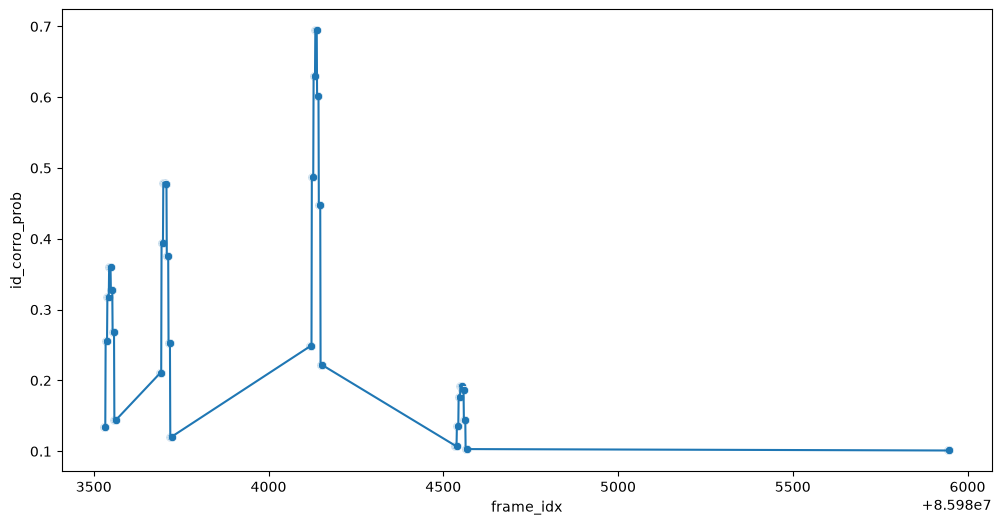

In [144]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.lineplot(data=full_df.query('id_corro_prob >= 0.1'), x="frame_idx", y="id_corro_prob")
sns.scatterplot(data=full_df.query('id_corro_prob >= 0.1'), x="frame_idx", y="id_corro_prob")

In [146]:
# Run function
prominence_thresh = 0.3
energy_threshold = 0.5
marked_peaks_df = label_defects_fast_no_overlap(full_df,'frame_idx','id_corro_prob', prominence_thresh, energy_threshold)
marked_peaks_df.query('defect_marker > 0')

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,defect_marker
33533,0AXVHCA77S1,01-000-1B3U2QML,0,85983533,3303729407,1555578222,0.134688,1
33534,0AXVHCA77S1,01-000-1B3U2QML,0,85983534,3303729453,1555578240,0.256126,1
33535,0AXVHCA77S1,01-000-1B3U2QML,0,85983535,3303729498,1555578258,0.256126,1
33536,0AXVHCA77S1,01-000-1B3U2QML,0,85983536,3303729543,1555578276,0.256126,1
33537,0AXVHCA77S1,01-000-1B3U2QML,0,85983537,3303729589,1555578294,0.256126,1
...,...,...,...,...,...,...,...,...
34144,0AXVHCA77S1,01-000-1B3U2QML,0,85984144,3303759048,1555589220,0.447417,3
34145,0AXVHCA77S1,01-000-1B3U2QML,0,85984145,3303759097,1555589238,0.447417,3
34146,0AXVHCA77S1,01-000-1B3U2QML,0,85984146,3303759146,1555589256,0.447417,3
34147,0AXVHCA77S1,01-000-1B3U2QML,0,85984147,3303759194,1555589274,0.447417,3


In [147]:
# group by marker
marked_peaks_grp_df = marked_peaks_df.query('defect_marker > 0')[['id_corro_prob','defect_marker']].groupby('defect_marker').agg(['mean','count','max','idxmax']).reset_index()
# Flatten the nested columns instantly
marked_peaks_grp_df.columns = [f"{col[0]}_{col[1]}" if col[1] else col[0] for col in marked_peaks_grp_df.columns]
display(marked_peaks_grp_df)
marked_peaks_df = marked_peaks_df.merge(marked_peaks_grp_df,left_on='defect_marker',right_on='defect_marker',how = 'outer').fillna(0)
marked_peaks_df

,defect_marker,id_corro_prob_mean,id_corro_prob_count,id_corro_prob_max,id_corro_prob_idxmax
0,1,0.293658,27,0.359642,33544
1,2,0.389048,26,0.479414,33699
2,3,0.559670,26,0.694222,34134


,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,defect_marker,id_corro_prob_mean,id_corro_prob_count,id_corro_prob_max,id_corro_prob_idxmax
0,0AXVHCA77S1,01-000-1B3U2QML,0,85950000,3302097331,1554974136,0.001918,0,0.00000,0.0,0.000000,0.0
1,0AXVHCA77S1,01-000-1B3U2QML,0,85950001,3302097376,1554974154,0.001918,0,0.00000,0.0,0.000000,0.0
2,0AXVHCA77S1,01-000-1B3U2QML,0,85950002,3302097422,1554974172,0.001918,0,0.00000,0.0,0.000000,0.0
3,0AXVHCA77S1,01-000-1B3U2QML,0,85950003,3302097467,1554974190,0.001918,0,0.00000,0.0,0.000000,0.0
4,0AXVHCA77S1,01-000-1B3U2QML,0,85950004,3302097513,1554974208,0.001918,0,0.00000,0.0,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,0AXVHCA77S1,01-000-1B3U2QML,0,85984144,3303759048,1555589220,0.447417,3,0.55967,26.0,0.694222,34134.0
49996,0AXVHCA77S1,01-000-1B3U2QML,0,85984145,3303759097,1555589238,0.447417,3,0.55967,26.0,0.694222,34134.0
49997,0AXVHCA77S1,01-000-1B3U2QML,0,85984146,3303759146,1555589256,0.447417,3,0.55967,26.0,0.694222,34134.0
49998,0AXVHCA77S1,01-000-1B3U2QML,0,85984147,3303759194,1555589274,0.447417,3,0.55967,26.0,0.694222,34134.0


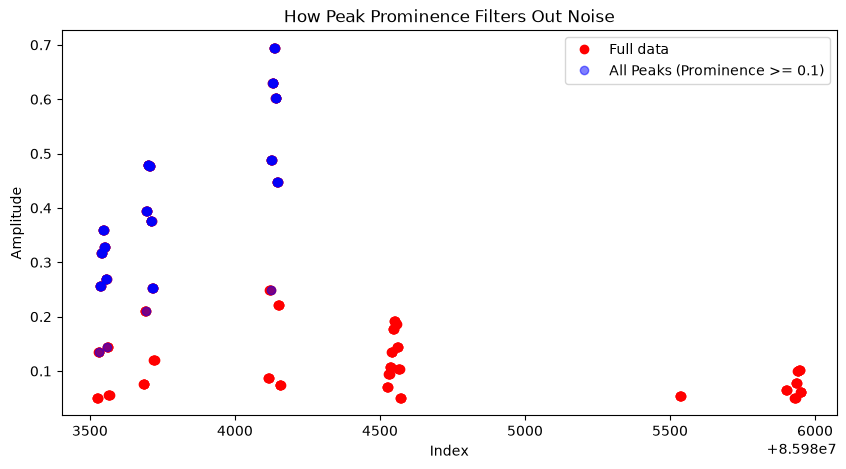

In [148]:
# Visual Comparison
plt.figure(figsize=(10, 5))
plt.plot(marked_peaks_df.query('id_corro_prob >= 0.05')['frame_idx'], marked_peaks_df.query('id_corro_prob >= 0.05')['id_corro_prob'], "o", label="Full data", color="red")
plt.plot(marked_peaks_df.query('defect_marker > 0 and id_corro_prob >= 0.05')['frame_idx'], marked_peaks_df.query('defect_marker > 0 and id_corro_prob >= 0.05')['id_corro_prob'], "o", label="All Peaks (Prominence >= 0.1)", color="blue",alpha = 0.5)
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.legend()
plt.title("How Peak Prominence Filters Out Noise")
plt.show()

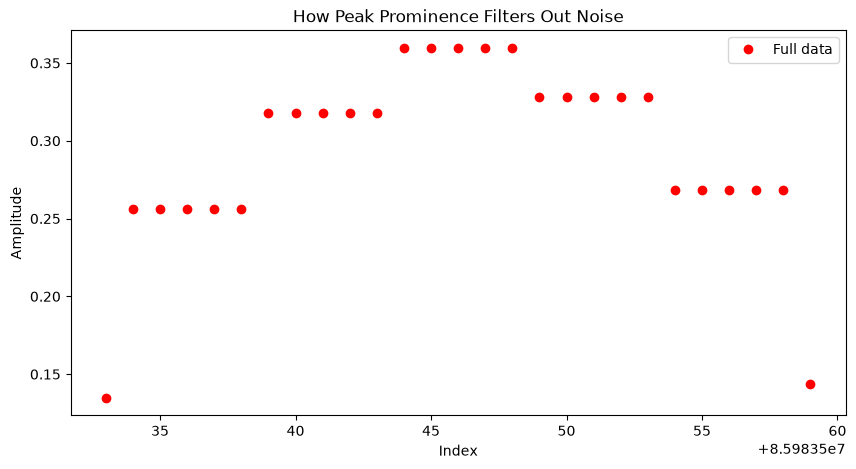

In [149]:
# Visual Comparison
plt.figure(figsize=(10, 5))
plt.plot(marked_peaks_df.query('defect_marker == 1')['frame_idx'], marked_peaks_df.query('defect_marker == 1')['id_corro_prob'], "o", label="Full data", color="red")
# plt.plot(marked_peaks_df.query('defect_marker > 0 and id_corro_prob >= 0.05')['frame_idx'], marked_peaks_df.query('defect_marker > 0 and id_corro_prob >= 0.05')['id_corro_prob'], "o", label="All Peaks (Prominence >= 0.1)", color="blue",alpha = 0.5)
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.legend()
plt.title("How Peak Prominence Filters Out Noise")
plt.show()

In [ ]:


def label_symmetric_cutoff_defect_regions(df, x_col="x", y_col="y", prominence_thresh=0.2, cutoff_fraction=0.50):
    """
    Identifies peaks and applies a symmetric horizontal cutoff. It evaluates 
    the local floors on both sides, picks the one that represents the larger 
    drop from the peak apex, and uses that height level to clip both boundaries.
    """
    x = df[x_col].values
    y = df[y_col].values
    
    # 1. Detect peaks and extract structural bases
    peaks, _ = signal.find_peaks(y, prominence=prominence_thresh)
    num_peaks = len(peaks)
    
    df["defect_marker"] = 0
    if num_peaks == 0:
        return df

    proms, left_bases, right_bases = signal.peak_prominences(y, peaks)
    
    # 2. Initialize boundary arrays for overlap prevention
    final_left_bounds = np.copy(left_bases)
    final_right_bounds = np.copy(right_bases)
    
    # 3. Enforce strict non-overlapping limits between adjacent peaks
    for i in range(num_peaks):
        if i > 0:
            valley_idx = prev_peak + np.argmin(y[prev_peak:peaks[i]])
            final_left_bounds[i] = max(final_left_bounds[i], valley_idx, final_right_bounds[i-1] + 1)
        if i < num_peaks - 1:
            next_peak = peaks[i+1]
            valley_idx = peaks[i] + np.argmin(y[peaks[i]:next_peak])
            final_right_bounds[i] = min(final_right_bounds[i], valley_idx)
        prev_peak = peaks[i]

    # 4. Map boundaries symmetrically using the largest-drop threshold level
    for i in range(num_peaks):
        peak_idx = peaks[i]
        start_idx = int(final_left_bounds[i])
        end_idx = int(final_right_bounds[i])
        peak_val = y[peak_idx]
        
        # Look at the baseline values at both domain boundaries
        left_floor = y[start_idx]
        right_floor = y[end_idx]
        
        # Calculate the two individual drops from the peak apex
        left_drop = peak_val - left_floor
        right_drop = peak_val - right_floor
        
        # CRITICAL FIX: Identify which side requires the larger drop from the apex
        # Using the MINIMUM floor guarantees we use the larger drop distance
        lower_floor = min(left_floor, right_floor)
        max_drop = max(left_drop, right_drop)
        
        # Calculate the absolute target cutoff height level uniformly for both sides
        target_cutoff_value = peak_val - (cutoff_fraction * max_drop)
        
        # Extract profiles inside the safe boundaries
        left_profile = y[start_idx:peak_idx+1]
        right_profile = y[peak_idx:end_idx+1]
        
        # Find where the signal falls below this uniform target value moving away from the apex
        left_matches = np.where(left_profile <= target_cutoff_value)[0]
        right_matches = np.where(right_profile <= target_cutoff_value)[0]
        
        # Resolve indices cleanly using pure scalar slicing
        left_extent_idx = start_idx + left_matches[-1] if len(left_matches) > 0 else start_idx
        right_extent_idx = peak_idx + right_matches[0] if len(right_matches) > 0 else end_idx
        
        # Label the dataframe rows
        df.loc[left_extent_idx:right_extent_idx, "defect_marker"] = i + 1
        
    return df


In [ ]:
# other possible functions

import numpy as np
import scipy.signal as signal

def label_defects_fast(df, x_col="x", y_col="y", prominence=0.2, cutoff=0.50):
    # 1. Find the peak apexes and calculate their exact widths instantly
    peaks, _ = signal.find_peaks(df[y_col], prominence=prominence)
    _, _, left_ips, right_ips = signal.peak_widths(df[y_col], peaks, rel_height=cutoff)
    
    # 2. Convert interpolated floating-point boundaries to round integer row indices
    left_indices = np.clip(np.round(left_ips).astype(int), 0, len(df)-1)
    right_indices = np.clip(np.round(right_ips).astype(int), 0, len(df)-1)
    
    # 3. Apply the IDs to the dataframe rows without a heavy manual lookup loop
    df["defect_marker"] = 0
    for i, (start, end) in enumerate(zip(left_indices, right_indices)):
        df.loc[start:end, "defect_marker"] = i + 1
        
    return df


import numpy as np
import scipy.signal as signal

def label_defects_fast_no_overlap(df, x_col="x", y_col="y", prominence=0.2, cutoff=0.50):
    # 1. Find peaks and symmetric intersection points instantly
    peaks, _ = signal.find_peaks(df[y_col], prominence=prominence)
    _, _, left_ips, right_ips = signal.peak_widths(df[y_col], peaks, rel_height=cutoff)
    
    # Round to absolute integer row indices
    left_idx = np.round(left_ips).astype(int)
    right_idx = np.round(right_ips).astype(int)
    
    # 2. Vectorized Overlap Check: Fix boundaries between adjacent peaks
    if len(peaks) > 1:
        # Find where a peak's right edge oversteps the next peak's left edge
        overlaps = right_idx[:-1] >= left_idx[1:]
        if np.any(overlaps):
            # Calculate the exact integer midpoint between the two conflicting boundaries
            midpoints = ((right_idx[:-1] + left_idx[1:]) // 2).astype(int)
            # Clip the left peak's right bound and the right peak's left bound at the midpoint
            right_idx[:-1] = np.where(overlaps, midpoints, right_idx[:-1])
            left_idx[1:] = np.where(overlaps, midpoints + 1, left_idx[1:])

    # 3. Apply the IDs to the dataframe rows
    df["defect_marker"] = 0
    for i, (start, end) in enumerate(zip(left_idx, right_idx)):
        df.loc[start:end, "defect_marker"] = i + 1
        
    return df



# Application to full dataset

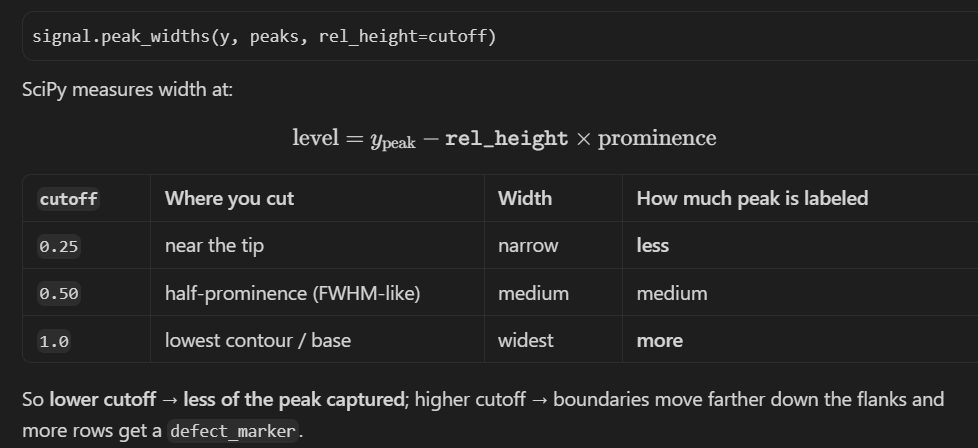


In [117]:
def label_defects_fast_no_overlap_sym(df, x_col, y_col, prominence, cutoff):

    """Identifies peak-based anomalies and applies a strict, non-overlapping label mask.

    This function locates peak apexes using prominence thresholds, maps their symmetric
    boundaries using fractional height cutoffs via linear interpolation, vectorizes 
    and resolves boundary conflicts using midpoint splitting, and updates the input 
    DataFrame with sequential integer defect group IDs.

    Args:
        df (pandas.DataFrame): The source dataset containing signal data rows.
        x_col (str): Column name for coordinates/telemetry (e.g., time, distance). 
            Defaults to "x".
        y_col (str): Column name for the raw signal amplitude data. 
            Defaults to "y".
        prominence (float): Minimum required relative height threshold 
            for SciPy peak detection
        cutoff (float): The fractional height level (0.0 to 1.0) measured 
            from the local baseline where boundaries clip (e.g., 0.50 is FWHM). 
            Defaults to 0.50.

    Returns:
        pandas.DataFrame: The original DataFrame updated with a 'defect_marker' column. 
            Background data is assigned 0. Defect regions are sequentially tagged 
            with integer IDs (1, 2, 3...).

    Raises:
        KeyError: If either `x_col` or `y_col` does not exist in the DataFrame.
        ValueError: If `cutoff` is outside the required 0.0 to 1.0 range.
    """
    # 1. Find peaks and symmetric intersection points instantly
    peaks, _ = signal.find_peaks(df[y_col], prominence=prominence)
    _, _, left_ips, right_ips = signal.peak_widths(df[y_col], peaks, rel_height=cutoff)
    
    # Round to absolute integer row indices
    left_idx = np.round(left_ips).astype(int)
    right_idx = np.round(right_ips).astype(int)
    
    # 2. Vectorized Overlap Check: Fix boundaries between adjacent peaks
    if len(peaks) > 1:
        # Find where a peak's right edge oversteps the next peak's left edge
        overlaps = right_idx[:-1] >= left_idx[1:]
        if np.any(overlaps):
            # Calculate the exact integer midpoint between the two conflicting boundaries
            midpoints = ((right_idx[:-1] + left_idx[1:]) // 2).astype(int)
            # Clip the left peak's right bound and the right peak's left bound at the midpoint
            right_idx[:-1] = np.where(overlaps, midpoints, right_idx[:-1])
            left_idx[1:] = np.where(overlaps, midpoints + 1, left_idx[1:])

    # 3. Apply the IDs to the dataframe rows
    df["defect_marker"] = 0
    for i, (start, end) in enumerate(zip(left_idx, right_idx)):
        df.loc[start:end, "defect_marker"] = i + 1
        
    return df

def _one_sided_prominences(y, peaks):
    """Left/right drop from peak to min on each side within SciPy bases."""
    _, left_bases, right_bases = signal.peak_prominences(y, peaks)
    left_prom = np.empty(len(peaks), dtype=float)
    right_prom = np.empty(len(peaks), dtype=float)
    for i, (p, lb, rb) in enumerate(zip(peaks, left_bases, right_bases)):
        left_prom[i] = y[p] - y[lb : p + 1].min()
        right_prom[i] = y[p] - y[p : rb + 1].min()
    return left_prom, right_prom


# def label_defects_fast_no_overlap(df, x_col, y_col, prominence, cutoff):
#     """
#     Peak labeling with asymmetric (one-sided) prominence.

#     A peak is kept if max(left_prominence, right_prominence) >= prominence,
#     i.e. it is prominent on at least one side (shoulders / asymmetric hills).
#     """
#     if not 0.0 <= cutoff <= 1.0:
#         raise ValueError("cutoff must be in [0.0, 1.0]")
#     if x_col not in df.columns or y_col not in df.columns:
#         raise KeyError(f"Missing column(s): {x_col}, {y_col}")

#     y = df[y_col].to_numpy(dtype=float)

#     # 1. Candidate local maxima (no two-sided prominence filter)
#     peaks, _ = signal.find_peaks(y, plateau_size=(None, 20))
#     if len(peaks) == 0:
#         df = df.copy()
#         df["defect_marker"] = 0
#         return df

#     # 2. Asymmetric prominence filter
#     left_prom, right_prom = _one_sided_prominences(y, peaks)
#     keep = np.maximum(left_prom, right_prom) >= prominence
#     # equivalent: (left_prom >= prominence) | (right_prom >= prominence)
#     peaks = peaks[keep]
#     if len(peaks) == 0:
#         df = df.copy()
#         df["defect_marker"] = 0
#         return df

#     # 3. Widths at fractional height (still uses SciPy's two-sided def for width)
#     _, _, left_ips, right_ips = signal.peak_widths(y, peaks, rel_height=cutoff)
#     left_idx = np.clip(np.round(left_ips).astype(int), 0, len(df) - 1)
#     right_idx = np.clip(np.round(right_ips).astype(int), 0, len(df) - 1)

#     # 4. Resolve overlaps at midpoints
#     if len(peaks) > 1:
#         overlaps = right_idx[:-1] >= left_idx[1:]
#         if np.any(overlaps):
#             midpoints = ((right_idx[:-1] + left_idx[1:]) // 2).astype(int)
#             right_idx[:-1] = np.where(overlaps, midpoints, right_idx[:-1])
#             left_idx[1:] = np.where(overlaps, midpoints + 1, left_idx[1:])

#     # 5. Label by position (iloc — peak_widths indices are positions, not labels)
#     df = df.copy()
#     df["defect_marker"] = 0
#     for i, (start, end) in enumerate(zip(left_idx, right_idx)):
#         if start > end:
#             start, end = end, start
#         df.iloc[start : end + 1, df.columns.get_loc("defect_marker")] = i + 1

#     return df

def label_defects_fast_no_overlap(
    df: pd.DataFrame,
    x_col: str,
    y_col: str,
    prominence: float,
    cutoff: float,
    plateau_size=(None, 20),
) -> pd.DataFrame:
    """
    Find peaks, take width at `cutoff` (rel_height), resolve overlaps by
    midpoint split, then assign defect IDs so that:
      - adjacent touching intervals share the same marker
      - marker increments only when there is a gap between intervals
      - unmarked rows stay 0
    """
    if not 0.0 <= cutoff <= 1.0:
        raise ValueError("cutoff must be in [0.0, 1.0]")
    if x_col not in df.columns or y_col not in df.columns:
        raise KeyError(f"Missing column(s): {x_col}, {y_col}")
    out = df.copy()
    y = out[y_col].to_numpy(dtype=float)
    n = len(out)
    peaks, _ = signal.find_peaks(y, prominence=prominence, plateau_size=plateau_size)
    out["defect_marker"] = 0
    if len(peaks) == 0:
        return out
    _, _, left_ips, right_ips = signal.peak_widths(y, peaks, rel_height=cutoff)
    left_idx = np.clip(np.round(left_ips).astype(int), 0, n - 1)
    right_idx = np.clip(np.round(right_ips).astype(int), 0, n - 1)
    # Ensure left <= right
    swap = left_idx > right_idx
    left_idx[swap], right_idx[swap] = right_idx[swap], left_idx[swap]
    # Midpoint split for overlapping neighbors
    if len(peaks) > 1:
        overlaps = right_idx[:-1] >= left_idx[1:]
        if np.any(overlaps):
            midpoints = ((right_idx[:-1] + left_idx[1:]) // 2).astype(int)
            right_idx[:-1] = np.where(overlaps, midpoints, right_idx[:-1])
            left_idx[1:] = np.where(overlaps, midpoints + 1, left_idx[1:])
    # Assign IDs: increment only when there is a gap after the previous interval
    marker_col = out.columns.get_loc("defect_marker")
    defect_id = 0
    prev_end = -2  # so the first peak always starts a new ID
    for start, end in zip(left_idx, right_idx):
        if start > end:
            continue
        # gap if start >= prev_end + 2 (one or more unmarked samples between)
        # touch if start == prev_end + 1 → same ID
        if start > prev_end + 1:
            defect_id += 1
        out.iloc[start : end + 1, marker_col] = defect_id
        prev_end = max(prev_end, end)
    return out

def grouper(marked_peaks_df): 
    # group by marker
    marked_peaks_grp_df = marked_peaks_df.query('defect_marker > 0')[['id_corro_prob','defect_marker']].groupby('defect_marker').agg(['mean','count','max']).reset_index()
    # Flatten the nested columns instantly
    marked_peaks_grp_df.columns = [f"{col[0]}_{col[1]}" if col[1] else col[0] for col in marked_peaks_grp_df.columns]
    marked_peaks_df = marked_peaks_df.merge(marked_peaks_grp_df,left_on='defect_marker',right_on='defect_marker',how = 'outer').fillna(0)
    return marked_peaks_df

In [293]:
files_track = glob.glob(
    "/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/"
    "data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_06/*/0/*parquet"
)

parts = []
defect_id_offset = 0

for file in tqdm(files_track):
    df = pd.read_parquet(file)
    prominence_thresh = 0.05
    cutoff_threshold = 0.5
    # df = df.query("id_corro_prob > 0.05")
    if len(df) == 0:
        continue

    marked_peaks_df = label_defects_fast_no_overlap(
        df, "frame_idx", "id_corro_prob", prominence_thresh, cutoff_threshold
    )
    marked_peaks_df = marked_peaks_df.query("defect_marker > 0")
    marked_peaks_df = marked_peaks_df.query("id_corro_prob > 0.05")
    if len(marked_peaks_df) == 0:
        continue
    marked_peaks_df = grouper(marked_peaks_df)

    if len(marked_peaks_df):
        marked_peaks_df = marked_peaks_df.copy()
        marked_peaks_df["defect_marker"] += defect_id_offset
        defect_id_offset = int(marked_peaks_df["defect_marker"].max())
        parts.append(marked_peaks_df)

defectDF = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
defectDF = defectDF.rename(columns={
    "id_corro_prob_count": "length",
    "id_corro_prob_max": "vol_conf",
})

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1935/1935 [00:16<00:00, 117.10it/s]


In [129]:
display(defectDF.query('id_corro_prob_mean > 0.8'))
print(defectDF.query('id_corro_prob_mean > 0.8')['defect_marker'].unique())

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,defect_marker,id_corro_prob_mean,length,vol_conf
122,0AXVHCA77S1,01-009-1B3U2V9R,9,85464158,3278233548,1546438632,0.471096,6,0.865632,47,0.977063
123,0AXVHCA77S1,01-009-1B3U2V9R,9,85464159,3278233598,1546438650,0.747171,6,0.865632,47,0.977063
124,0AXVHCA77S1,01-009-1B3U2V9R,9,85464160,3278233646,1546438668,0.747171,6,0.865632,47,0.977063
125,0AXVHCA77S1,01-009-1B3U2V9R,9,85464161,3278233697,1546438686,0.747171,6,0.865632,47,0.977063
126,0AXVHCA77S1,01-009-1B3U2V9R,9,85464162,3278233745,1546438704,0.747171,6,0.865632,47,0.977063
...,...,...,...,...,...,...,...,...,...,...,...
26315,0AXVHCA77S1,01-009-1B3U2V9R,9,20335004,666277561,367909392,0.627989,984,0.815800,30,0.966901
26316,0AXVHCA77S1,01-009-1B3U2V9R,9,20335005,666277615,367909428,0.627989,984,0.815800,30,0.966901
26317,0AXVHCA77S1,01-009-1B3U2V9R,9,20335006,666277642,367909446,0.627989,984,0.815800,30,0.966901
26318,0AXVHCA77S1,01-009-1B3U2V9R,9,20335007,666277669,367909464,0.627989,984,0.815800,30,0.966901


[  6 127 610 867 919 984]


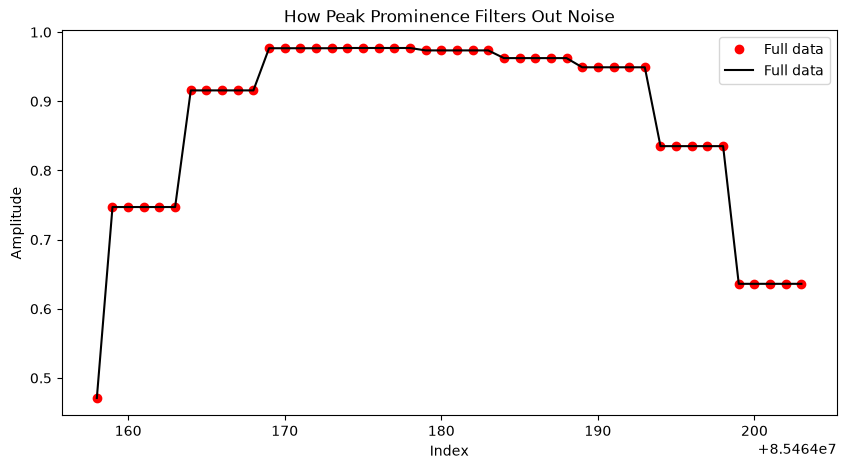

In [120]:
# Visual Comparison
marker = 6
plt.figure(figsize=(10, 5))
plt.plot(defectDF.query('defect_marker == @marker')['frame_idx'], defectDF.query('defect_marker == @marker')['id_corro_prob'], "o", label="Full data", color="red")
plt.plot(defectDF.query('defect_marker == @marker')['frame_idx'], defectDF.query('defect_marker == @marker')['id_corro_prob'], "k-", label="Full data")
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.legend()
plt.title("How Peak Prominence Filters Out Noise")
plt.show()

In [121]:
markers = np.arange(0.1, 1.01, 0.05)  # includes 1.0; no rounding

def nearest_marker(x, markers=markers):
    x = np.asarray(x, dtype=float)
    idx = np.abs(x[:, None] - markers[None, :]).argmin(axis=1)
    out = markers[idx]
    out[np.isnan(x)] = np.nan
    return out

defectDF["bin_size"] = np.round(nearest_marker(defectDF["vol_conf"].to_numpy()),2)
defectDF

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,defect_marker,id_corro_prob_mean,length,vol_conf,bin_size
0,0AXVHCA77S1,01-009-1B3U2V9R,9,49683013,1585576164,898980744,0.253951,1,0.443770,22,0.515338,0.50
1,0AXVHCA77S1,01-009-1B3U2V9R,9,49683014,1585576200,898980762,0.415855,1,0.443770,22,0.515338,0.50
2,0AXVHCA77S1,01-009-1B3U2V9R,9,49683015,1585576235,898980780,0.415855,1,0.443770,22,0.515338,0.50
3,0AXVHCA77S1,01-009-1B3U2V9R,9,49683016,1585576270,898980798,0.415855,1,0.443770,22,0.515338,0.50
4,0AXVHCA77S1,01-009-1B3U2V9R,9,49683017,1585576305,898980816,0.415855,1,0.443770,22,0.515338,0.50
...,...,...,...,...,...,...,...,...,...,...,...,...
20526,0AXVHCA77S1,01-009-1B3U2V9R,9,57612629,1895540607,1042489038,0.343740,809,0.382292,25,0.464364,0.45
20527,0AXVHCA77S1,01-009-1B3U2V9R,9,57612630,1895540655,1042489056,0.343740,809,0.382292,25,0.464364,0.45
20528,0AXVHCA77S1,01-009-1B3U2V9R,9,57612631,1895540750,1042489092,0.343740,809,0.382292,25,0.464364,0.45
20529,0AXVHCA77S1,01-009-1B3U2V9R,9,57612632,1895540798,1042489110,0.343740,809,0.382292,25,0.464364,0.45


In [122]:
defectDF['bin_size'].unique()

array([0.5 , 0.85, 0.75, 0.8 , 1.  , 0.55, 0.45, 0.65, 0.4 , 0.6 , 0.95,
       0.7 , 0.9 , 0.35])

In [123]:
defectDF

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,defect_marker,id_corro_prob_mean,length,vol_conf,bin_size
0,0AXVHCA77S1,01-009-1B3U2V9R,9,49683013,1585576164,898980744,0.253951,1,0.443770,22,0.515338,0.50
1,0AXVHCA77S1,01-009-1B3U2V9R,9,49683014,1585576200,898980762,0.415855,1,0.443770,22,0.515338,0.50
2,0AXVHCA77S1,01-009-1B3U2V9R,9,49683015,1585576235,898980780,0.415855,1,0.443770,22,0.515338,0.50
3,0AXVHCA77S1,01-009-1B3U2V9R,9,49683016,1585576270,898980798,0.415855,1,0.443770,22,0.515338,0.50
4,0AXVHCA77S1,01-009-1B3U2V9R,9,49683017,1585576305,898980816,0.415855,1,0.443770,22,0.515338,0.50
...,...,...,...,...,...,...,...,...,...,...,...,...
20526,0AXVHCA77S1,01-009-1B3U2V9R,9,57612629,1895540607,1042489038,0.343740,809,0.382292,25,0.464364,0.45
20527,0AXVHCA77S1,01-009-1B3U2V9R,9,57612630,1895540655,1042489056,0.343740,809,0.382292,25,0.464364,0.45
20528,0AXVHCA77S1,01-009-1B3U2V9R,9,57612631,1895540750,1042489092,0.343740,809,0.382292,25,0.464364,0.45
20529,0AXVHCA77S1,01-009-1B3U2V9R,9,57612632,1895540798,1042489110,0.343740,809,0.382292,25,0.464364,0.45


/tmp/ipykernel_566306/92273940.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=defectDF, x="bin_size",palette="rainbow", bins = 40)


<Axes: xlabel='bin_size', ylabel='Count'>

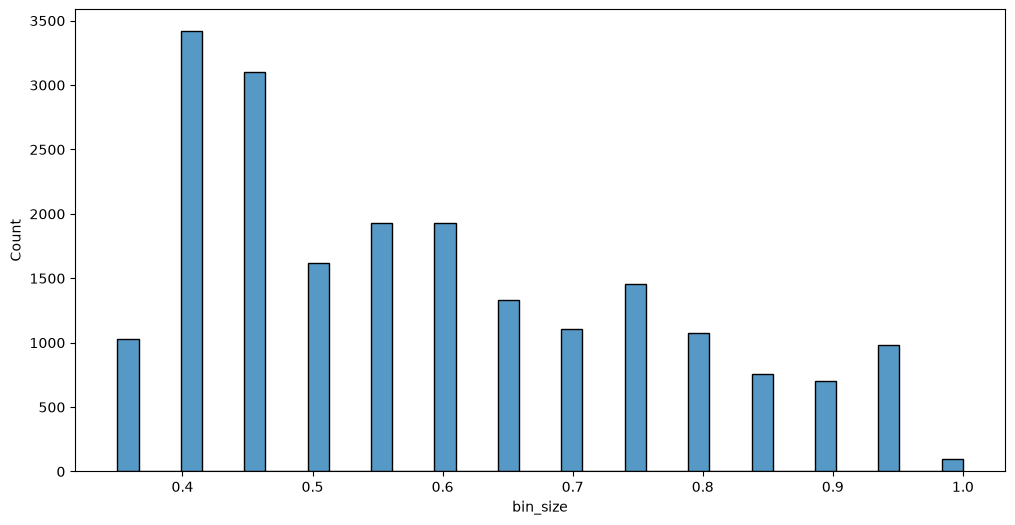

In [124]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.histplot(data=defectDF, x="bin_size",palette="rainbow", bins = 40)

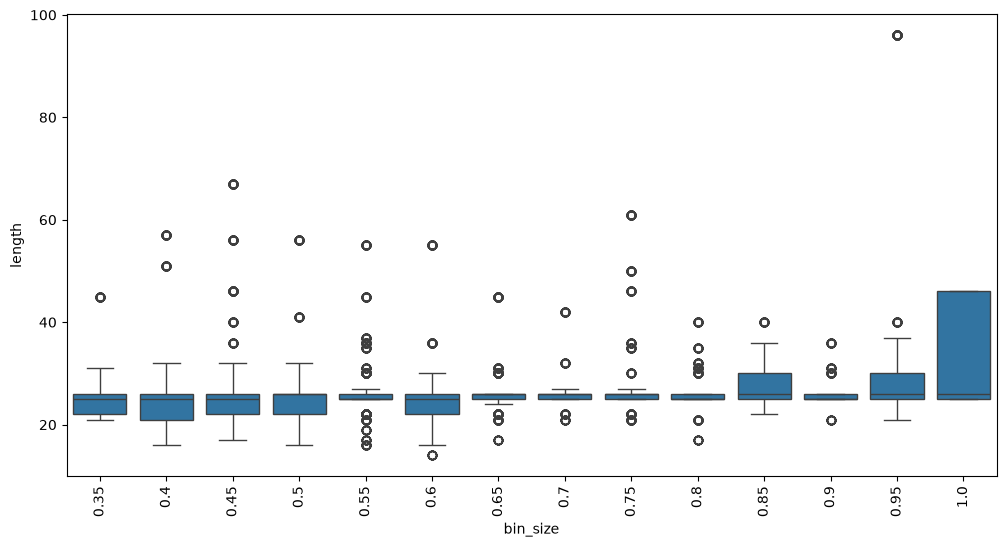

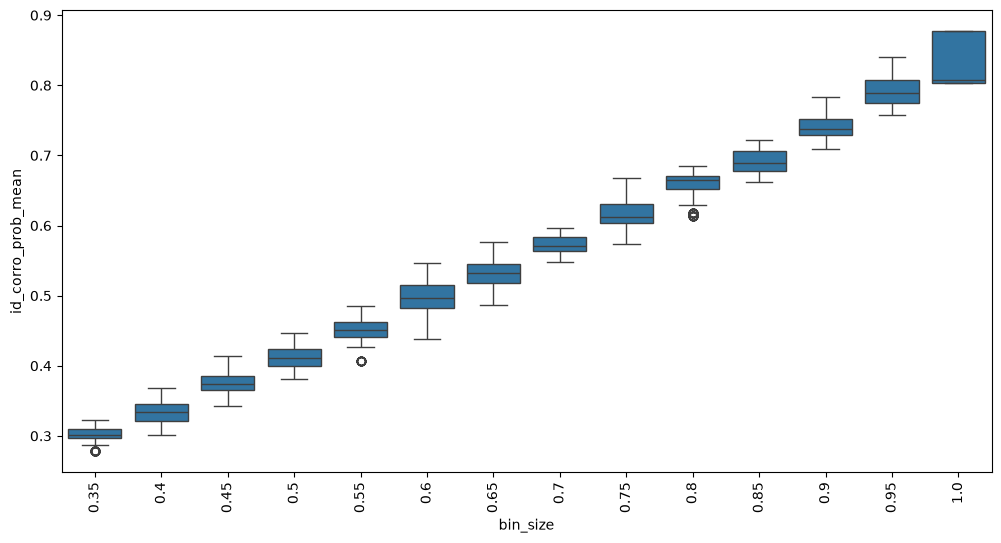

In [125]:
fig, ax= plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.boxplot(data=defectDF, x="bin_size", y="length")
ax.tick_params(axis="x", rotation=90)

fig, ax= plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.boxplot(data=defectDF, x="bin_size", y="id_corro_prob_mean")
ax.tick_params(axis="x", rotation=90)

In [126]:
defectDF[['vol_conf','bin_size']].groupby('bin_size').agg(['mean','max','min','std','count']).round(2)

vol_conf                        
             mean   max   min   std count
bin_size                                 
0.35         0.37  0.37  0.35  0.01  1030
0.40         0.40  0.42  0.38  0.01  3416
0.45         0.45  0.47  0.43  0.01  3102
0.50         0.50  0.52  0.48  0.02  1620
0.55         0.55  0.57  0.53  0.01  1928
0.60         0.60  0.62  0.58  0.01  1928
0.65         0.65  0.67  0.63  0.02  1328
0.70         0.70  0.72  0.68  0.01  1109
0.75         0.75  0.77  0.73  0.02  1457
0.80         0.80  0.82  0.78  0.01  1073
0.85         0.85  0.87  0.83  0.02   760
0.90         0.90  0.92  0.88  0.01   702
0.95         0.95  0.97  0.93  0.01   981
1.00         0.98  0.98  0.98  0.00    97

# reading the production file

In [352]:
df = pd.read_parquet('peaks_grouping_area.parquet')
display(df.query('bin_size == 0.1').sort_values(by = 'id_corro_prob'))
df["bin_size"] = df["bin_size"].round(2)
print(df.query('bin_size >= 0.7').sort_values(by = 'id_corro_prob')['defect_marker'].unique())
print(len(df.query('bin_size >= 0.7').sort_values(by = 'id_corro_prob')['defect_marker'].unique()))

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,defect_marker,id_corro_prob_mean,id_corro_prob_count,vol_conf,bin_size,frame_length
2490538,0AXVHCA77S1,01-014-1B3U2SOM,14,23638883,753508188,427632840,0.05,194432,0.078869,38,0.116033,0.1,58
2490536,0AXVHCA77S1,01-014-1B3U2SOM,14,23638881,753508134,427632804,0.05,194432,0.078869,38,0.116033,0.1,58
2490535,0AXVHCA77S1,01-014-1B3U2SOM,14,23638880,753508107,427632786,0.05,194432,0.078869,38,0.116033,0.1,58
2490537,0AXVHCA77S1,01-014-1B3U2SOM,14,23638882,753508162,427632822,0.05,194432,0.078869,38,0.116033,0.1,58
2490534,0AXVHCA77S1,01-014-1B3U2SOM,14,23638879,753508081,427632768,0.05,194432,0.078869,38,0.116033,0.1,58
...,...,...,...,...,...,...,...,...,...,...,...,...,...
907899,0AXVHCA77S1,01-006-1B3U30M8,6,79062315,2962707317,1430328804,0.15,72186,0.114806,30,0.150000,0.1,30
907898,0AXVHCA77S1,01-006-1B3U30M8,6,79062314,2962707264,1430328786,0.15,72186,0.114806,30,0.150000,0.1,30
907900,0AXVHCA77S1,01-006-1B3U30M8,6,79062316,2962707368,1430328822,0.15,72186,0.114806,30,0.150000,0.1,30
907902,0AXVHCA77S1,01-006-1B3U30M8,6,79062318,2962707471,1430328858,0.15,72186,0.114806,30,0.150000,0.1,30


[210676 118621 235181 ... 259283  59798 130973]
7089


In [327]:
# formatting to current deployment print out
defect_summary = (
    df.groupby("defect_marker", as_index=False)
    .agg(
        clip_id=("clip_id", "first"),
        track_id=("track_id", "first"),
        start_frame_idx=("frame_idx", "min"),
        end_frame_idx=("frame_idx", "max"),
        start_odo_ticks=("odometer_tick", "min"),
        end_odo_ticks=("odometer_tick", "max"),
        vol_conf=("vol_conf", "first"),
        id_corro_prob_mean=("id_corro_prob_mean", "first"),
        bin_size=("bin_size", "first"),
    )
    .assign(length_odo=lambda x: x["end_odo_ticks"] - x["start_odo_ticks"])
)

defect_summary = defect_summary[
    [
        "defect_marker",
        "clip_id",
        "track_id",
        "start_odo_ticks",
        "end_odo_ticks",
        "start_frame_idx",
        "end_frame_idx",
        "vol_conf",
        "id_corro_prob_mean",
        "bin_size",
        "length_odo"
    ]
]
base_defect_summary = defect_summary.query('bin_size >= 0.7').reset_index(drop = True)
lc_defect_summary = defect_summary.query('bin_size < 0.7').reset_index(drop = True)

base_defect_summary

,defect_marker,clip_id,track_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,id_corro_prob_mean,bin_size,length_odo
0,21,01-000-1B3U2QML,0,10737540,10737990,591593,591618,0.783206,0.626621,0.75,450
1,42,01-000-1B3U2QML,0,32013294,32013600,1766521,1766538,0.871058,0.766932,0.85,306
2,51,01-000-1B3U2QML,0,32109576,32109990,1771870,1771893,0.712927,0.654305,0.70,414
3,54,01-000-1B3U2QML,0,32113158,32113950,1772069,1772113,0.785500,0.428970,0.75,792
4,91,01-000-1B3U2QML,0,44630454,44633154,2463059,2463207,0.850672,0.314246,0.85,2700
...,...,...,...,...,...,...,...,...,...,...,...
7084,285296,01-021-1B3U30ZD,21,1707694896,1707695220,94384989,94385007,0.897543,0.794825,0.85,324
7085,285319,01-021-1B3U30ZD,21,1717631964,1717632324,94935104,94935124,0.749554,0.644651,0.70,360
7086,285344,01-021-1B3U30ZD,21,1722344532,1722344820,95195059,95195075,0.786416,0.714442,0.75,288
7087,285376,01-021-1B3U30ZD,21,1732561104,1732561752,95760678,95760713,0.716044,0.420748,0.70,648


In [328]:
counts = df[['inspection_id','bin_size']].groupby('bin_size').count().reset_index()
counts.rename(columns={'inspection_id':'count'},inplace = True)
counts['log_bin_size'] = np.log(counts['bin_size'])
counts['log_count']= np.log(counts['count'])
display(counts)

slope, intercept = np.polyfit(counts["log_bin_size"], counts["log_count"], 1)

print(f"Slope (m): {slope}")
print(f"Intercept (c): {intercept}")

,bin_size,count,log_bin_size,log_count
0,0.10,713502,-2.302585,13.477941
1,0.15,425554,-1.897120,12.961147
2,0.20,287010,-1.609438,12.567272
3,0.25,208255,-1.386294,12.246519
4,0.30,154711,-1.203973,11.949314
5,0.35,126462,-1.049822,11.747697
6,0.40,98440,-0.916291,11.497203
7,0.45,81934,-0.798508,11.313669
8,0.50,68641,-0.693147,11.136645
9,0.55,58287,-0.597837,10.973134


Slope (m): -1.4711247190037704
Intercept (c): 10.150752210773575


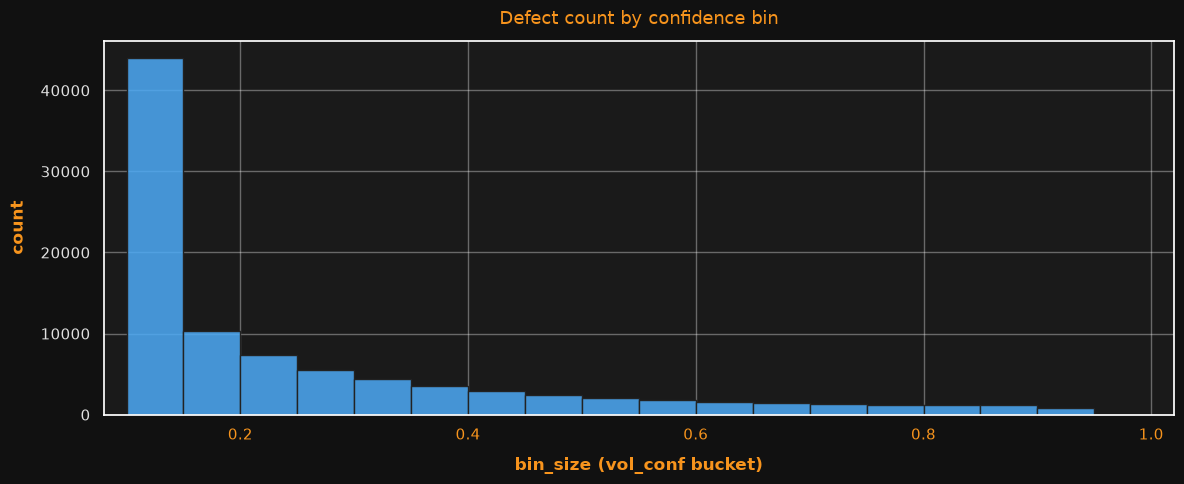

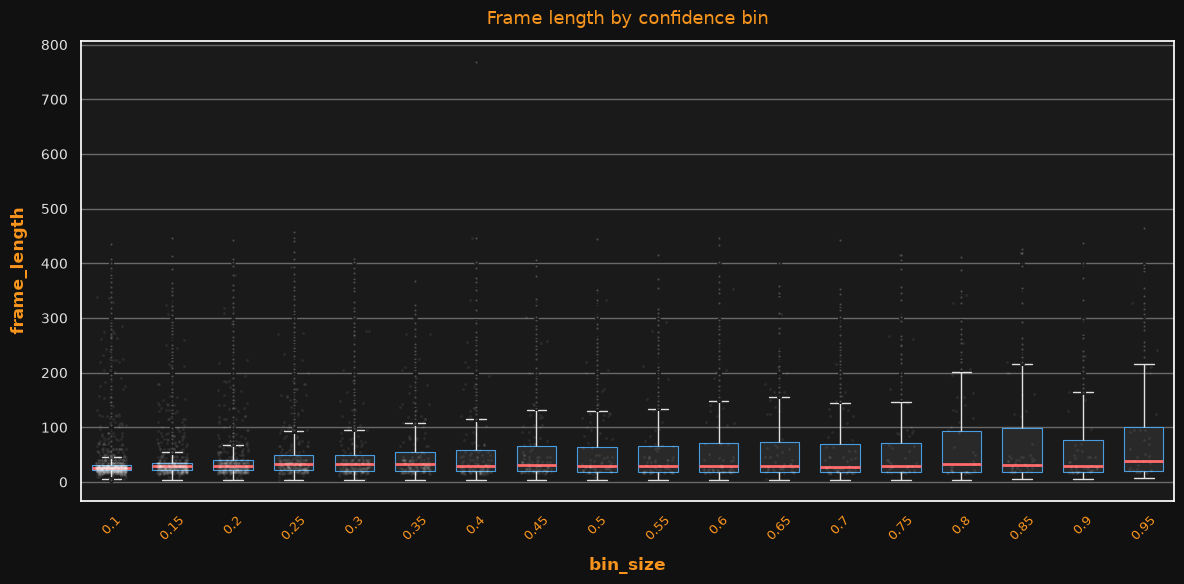

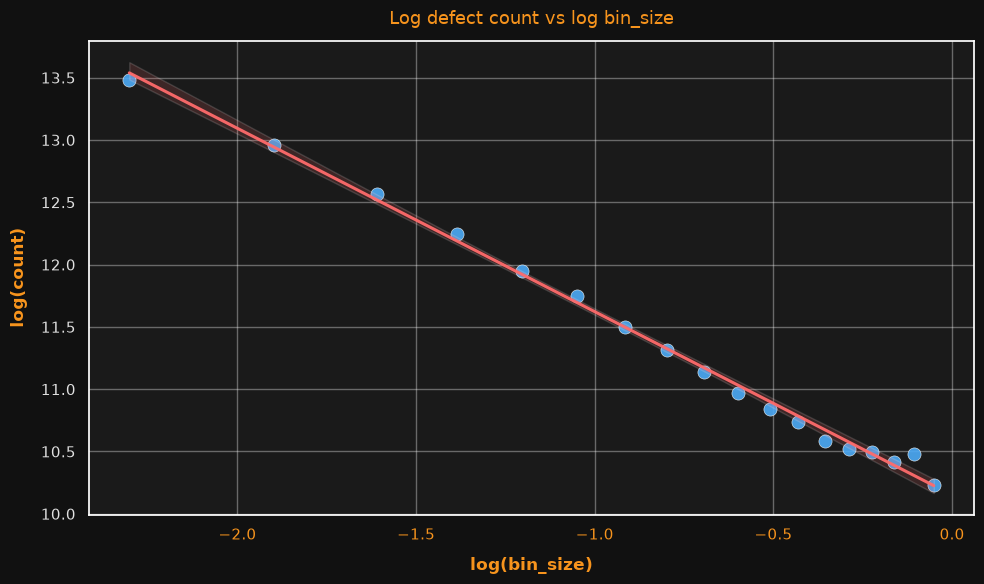

In [329]:
def style_axis_labels(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, color=DV_ORANGE, fontsize=12, fontweight="bold", labelpad=10)
    ax.set_ylabel(ylabel, color=DV_ORANGE, fontsize=12, fontweight="bold", labelpad=10)

# after each plot:


# ── dark theme ───────────────────────────────────────────────────────────────
# DV brand orange — swap hex if your style guide specifies a different one
DV_ORANGE = "#F7941D"
plt.rcParams.update({
    "figure.facecolor": "#111111",
    "axes.facecolor":   "#1a1a1a",
    "axes.edgecolor":   "#555555",
    "axes.labelcolor":  DV_ORANGE,   # ← x & y axis label color
    "axes.labelsize":   12,
    "axes.labelweight": "bold",
    "axes.titlecolor":  "#ffffff",
    "xtick.color":      "#cccccc",
    "ytick.color":      "#cccccc",
    "text.color":       "#e0e0e0",
    "grid.color":       "#333333",
    "grid.alpha":       0.35,
})
sns.set_theme(style="darkgrid", rc={
    "figure.facecolor": "#111111",
    "axes.facecolor":   "#1a1a1a",
    "xtick.color":      DV_ORANGE,
    "ytick.color":      "#e0e0e0",
})
# ── 1) bin_size distribution ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
edges = np.arange(0.10, 1.0 + 1e-9, 0.05)
sns.histplot(
    data=defect_summary,
    x="bin_size",
    bins=edges,
    color=ACCENT,
    edgecolor="#222222",
    alpha=0.85,
    ax=ax,
)
ax.set_title("Defect count by confidence bin", color=DV_ORANGE, fontsize=13, pad=12)
style_axis_labels(ax, "bin_size (vol_conf bucket)", "count")
ax.set_xlim(0.08, 1.02)
ax.grid(True, axis="y")
fig.tight_layout()
plt.show()
# ── 2) frame_length by bin_size ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))
# keep only bins with enough points so the plot isn't sparse noise
min_n = 5
bin_counts = df.groupby("bin_size")["frame_length"].transform("count")
plot_df = df.loc[bin_counts >= min_n].copy()
sns.boxplot(
    data=plot_df,
    x="bin_size",
    y="frame_length",
    color="#2b2b2b",
    linewidth=0.8,
    fliersize=2,
    width=0.65,
    boxprops=dict(edgecolor=ACCENT, alpha=0.9),
    medianprops=dict(color=ACCENT2, linewidth=2),
    whiskerprops=dict(color=TEXT, linewidth=1),
    capprops=dict(color=TEXT, linewidth=1),
    flierprops=dict(marker=".", markerfacecolor="#888", markersize=3, alpha=0.4),
    ax=ax,
)
# optional: show density of points behind boxes
sns.stripplot(
    data=plot_df.sample(min(len(plot_df), 3000), random_state=0),
    x="bin_size", y="frame_length",
    color="white", alpha=0.08, size=2, jitter=0.25, ax=ax,
)
ax.set_title("Frame length by confidence bin", color=DV_ORANGE, fontsize=13, pad=12)
ax.tick_params(axis="x", colors=DV_ORANGE, labelsize=9, rotation=45)
ax.tick_params(axis="y", colors="#e0e0e0", labelsize=10)
style_axis_labels(ax, "bin_size", "frame_length")
fig.tight_layout()
plt.show()
# ── 3) log-log counts vs bin_size ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=counts,
    x="log_bin_size",
    y="log_count",
    s=90,
    color=ACCENT,
    edgecolor="white",
    linewidth=0.4,
    alpha=0.9,
    ax=ax,
)
sns.regplot(
    data=counts,
    x="log_bin_size",
    y="log_count",
    scatter=False,
    color=ACCENT2,
    line_kws={"lw": 2.2, "alpha": 0.95},
    ax=ax,
)
ax.set_title("Log defect count vs log bin_size", color=DV_ORANGE, fontsize=13, pad=12)
style_axis_labels(ax, "log(bin_size)", "log(count)")
ax.grid(True)
fig.tight_layout()
plt.show()

# Compare with original

In [321]:
grouped_POR = pd.read_parquet('corrosion_v4.2_grouped.parquet')
grouped_POR

,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,anomaly_type
0,01-008-1B3U35Z7,64266,64608,1519,1538,0.766660,ID_CORRO_POS
1,01-017-1B3U2UAF,47580,47832,592,606,0.703444,ID_CORRO_POS
2,01-017-1B3U2UAF,48534,48840,645,662,0.837099,ID_CORRO_POS
3,01-013-1B3U3DTN,38616,39048,94,118,0.948382,ID_CORRO_POS
4,01-013-1B3U3DTN,39948,40290,168,187,0.942490,ID_CORRO_POS
...,...,...,...,...,...,...,...
7004,01-019-1B3U3DF1,1749703536,1749704238,96691514,96691553,0.902292,ID_CORRO_POS
7005,01-019-1B3U3DF1,1749706506,1749706938,96691679,96691703,0.776914,ID_CORRO_POS
7006,01-014-1B3U2SOM,1747346112,1747346544,96565294,96565318,0.955230,ID_CORRO_POS
7007,01-014-1B3U2SOM,1749614508,1749614760,96690399,96690413,0.725860,ID_CORRO_POS


In [330]:
por = grouped_POR.copy()
base = base_defect_summary.copy()

por["_por_idx"] = por.index
base["_base_idx"] = base.index

pairs = por.merge(base, on="clip_id", suffixes=("_por", "_base"))

overlaps = (
    (pairs["start_frame_idx_por"] <= pairs["end_frame_idx_base"])
    & (pairs["start_frame_idx_base"] <= pairs["end_frame_idx_por"])
)
pairs = pairs.loc[overlaps]

por_matched = set(pairs["_por_idx"])
base_matched = set(pairs["_base_idx"])

por["match_status"] = np.where(
    por.index.isin(por_matched), "both", "por_only"
)
base["match_status"] = np.where(
    base.index.isin(base_matched), "both", "base_only"
)

In [331]:
por['cent_odo'] = (por['start_odo_ticks'] + por['end_odo_ticks'])/2
base['cent_odo'] = (base['start_odo_ticks'] + base['end_odo_ticks'])/2

In [332]:
por.query('match_status != "both"')

,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,anomaly_type,_por_idx,match_status,cent_odo


In [333]:
base.query('match_status != "both"')

,defect_marker,clip_id,track_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,id_corro_prob_mean,bin_size,length_odo,_base_idx,match_status,cent_odo
610,27123,01-002-1B3U38Z5,2,1139183232,1139183538,62950546,62950563,0.710748,0.424132,0.70,306,610,base_only,1139183385.0
809,33785,01-003-1B3U2S7P,3,495993624,495993912,27400298,27400314,0.725263,0.230271,0.70,288,809,base_only,495993768.0
1216,51104,01-004-1B3U3B9G,4,1431279775,1431279865,79100639,79100644,0.733403,0.426890,0.70,90,1216,base_only,1431279820.0
2050,88650,01-007-1B3U2ZJ8,7,1487263470,1487263542,82200425,82200429,0.742007,0.434239,0.70,72,2050,base_only,1487263506.0
2581,104001,01-008-1B3U35Z7,8,1653899886,1653899994,91400125,91400131,0.840268,0.468576,0.80,108,2581,base_only,1653899940.0
3066,135667,01-010-1B3U324F,10,1167420204,1167420276,64550277,64550281,0.736642,0.649274,0.70,72,3066,base_only,1167420240.0
3523,155133,01-011-1B3U2R5Y,11,904743252,904743342,50000690,50000695,0.756316,0.617929,0.75,90,3523,base_only,904743297.0
5321,224309,01-016-1B3U360L,16,1308118320,1308118464,72300732,72300740,0.751618,0.377827,0.75,144,5321,base_only,1308118392.0
5792,238077,01-018-1B3U2ZX0,18,212612538,212612628,11750519,11750524,0.748030,0.422675,0.70,90,5792,base_only,212612583.0
5925,246351,01-018-1B3U2ZX0,18,1406779866,1406779992,77750475,77750482,0.723604,0.416785,0.70,126,5925,base_only,1406779929.0


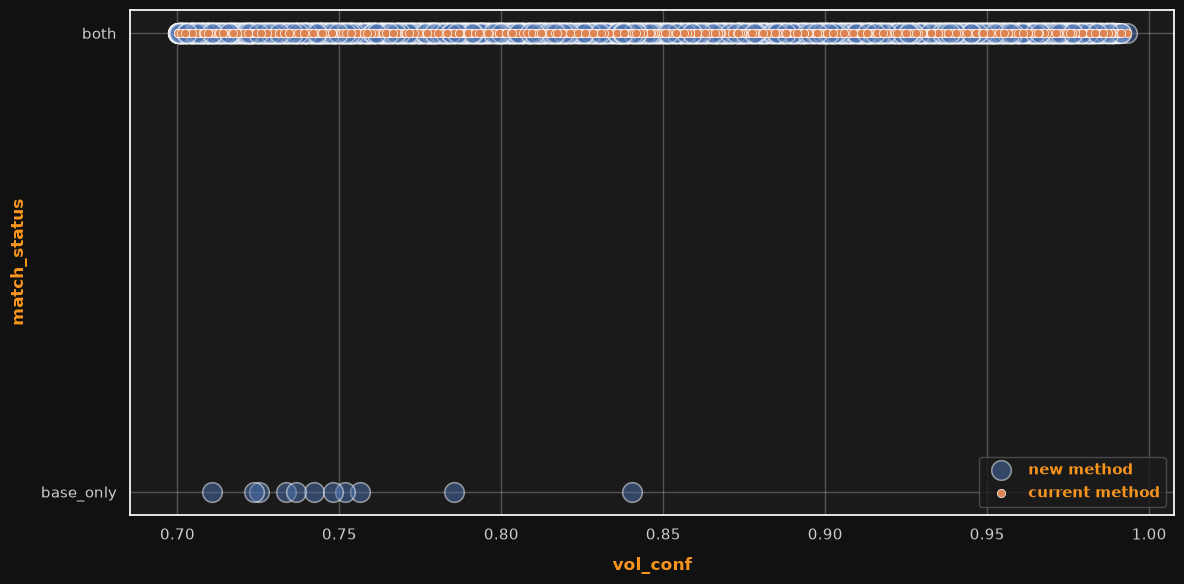

In [334]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), facecolor="#111111")
ax1.set_facecolor("#1a1a1a")
sns.scatterplot(data=base, x="vol_conf",y = 'match_status',label = 'new method', s= 200, alpha = 0.5)
sns.scatterplot(data=por, x="vol_conf",y = 'match_status',label = 'current method')

style_axis_labels(ax1, "vol_conf", "match_status")
leg = ax1.legend(
    loc="lower right",
    frameon=True,
    facecolor="#1a1a1a",
    edgecolor="#555555",
    labelcolor=DV_ORANGE,
    fontsize=11,
)
for text in leg.get_texts():
    text.set_color(DV_ORANGE)
    text.set_fontweight("semibold")
ax1.grid(True, alpha=0.25)
ax1.tick_params(axis="x", colors="#cccccc")
ax1.tick_params(axis="y", colors="#cccccc")
fig.tight_layout()
plt.show()

In [335]:
base.query('match_status != "both"')

,defect_marker,clip_id,track_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,id_corro_prob_mean,bin_size,length_odo,_base_idx,match_status,cent_odo
610,27123,01-002-1B3U38Z5,2,1139183232,1139183538,62950546,62950563,0.710748,0.424132,0.70,306,610,base_only,1139183385.0
809,33785,01-003-1B3U2S7P,3,495993624,495993912,27400298,27400314,0.725263,0.230271,0.70,288,809,base_only,495993768.0
1216,51104,01-004-1B3U3B9G,4,1431279775,1431279865,79100639,79100644,0.733403,0.426890,0.70,90,1216,base_only,1431279820.0
2050,88650,01-007-1B3U2ZJ8,7,1487263470,1487263542,82200425,82200429,0.742007,0.434239,0.70,72,2050,base_only,1487263506.0
2581,104001,01-008-1B3U35Z7,8,1653899886,1653899994,91400125,91400131,0.840268,0.468576,0.80,108,2581,base_only,1653899940.0
3066,135667,01-010-1B3U324F,10,1167420204,1167420276,64550277,64550281,0.736642,0.649274,0.70,72,3066,base_only,1167420240.0
3523,155133,01-011-1B3U2R5Y,11,904743252,904743342,50000690,50000695,0.756316,0.617929,0.75,90,3523,base_only,904743297.0
5321,224309,01-016-1B3U360L,16,1308118320,1308118464,72300732,72300740,0.751618,0.377827,0.75,144,5321,base_only,1308118392.0
5792,238077,01-018-1B3U2ZX0,18,212612538,212612628,11750519,11750524,0.748030,0.422675,0.70,90,5792,base_only,212612583.0
5925,246351,01-018-1B3U2ZX0,18,1406779866,1406779992,77750475,77750482,0.723604,0.416785,0.70,126,5925,base_only,1406779929.0


In [336]:
por.query('match_status != "both"')

,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,anomaly_type,_por_idx,match_status,cent_odo


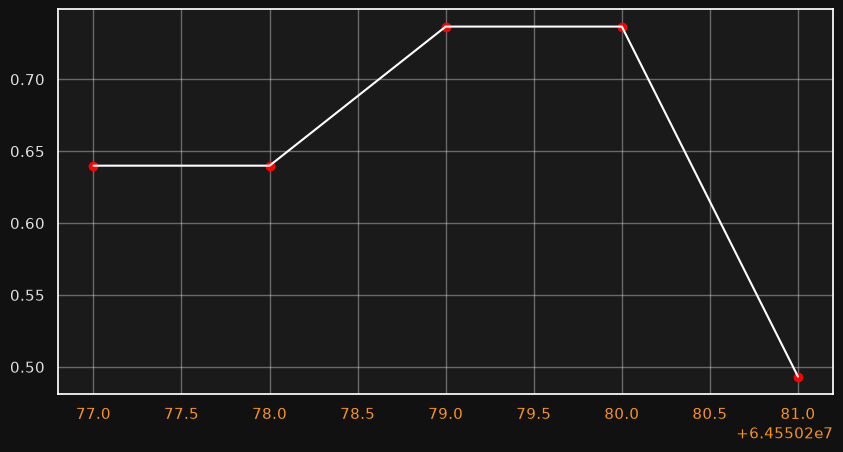

In [342]:
# Visual Comparison
marker = 135667			
plt.figure(figsize=(10, 5))
plt.plot(df.query('defect_marker == @marker')['frame_idx'], df.query('defect_marker == @marker')['id_corro_prob'], "o", label="Full data", color="red")
plt.plot(df.query('defect_marker == @marker')['frame_idx'], df.query('defect_marker == @marker')['id_corro_prob'], "w-", label="Full data")
style_axis_labels(ax, "Index", "Amplitude")
# plt.legend()
# plt.title("How Peak Prominence Filters Out Noise")
plt.show()

In [346]:
files_track_por = glob.glob('/home/sayakdg/ILI_workflow_dev/backuo/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_16/*/0/*parquet')
full_df = pd.DataFrame()
for file in tqdm(files_track_por):
    df_file = pd.read_parquet(file).query('id_corro_prob > 0.2').reset_index(drop = True)
    full_df = pd.concat([full_df,df_file])
# display(full_df) 

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1935/1935 [00:12<00:00, 154.85it/s]


# Comapre with cascade

In [343]:
cascadeDF = pd.read_parquet('lower_conf_thresh_0.1_0.05.parquet')

In [344]:
defect_summary['anomaly_type'] = 'ID_CORRO_POS' 

In [345]:
print(np.sort(cascadeDF['bin_size'].unique()))
print(np.sort(defect_summary['bin_size'].unique()))

[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9  0.95]
[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9  0.95  nan]


In [346]:
countsCascade = cascadeDF[['anomaly_type','bin_size']].groupby('bin_size').count().reset_index()
countsCascade.rename(columns={'anomaly_type':'count'},inplace = True)

countsDefect_summary = defect_summary[['anomaly_type','bin_size']].groupby('bin_size').count().reset_index()
countsDefect_summary.rename(columns={'anomaly_type':'count'},inplace = True)

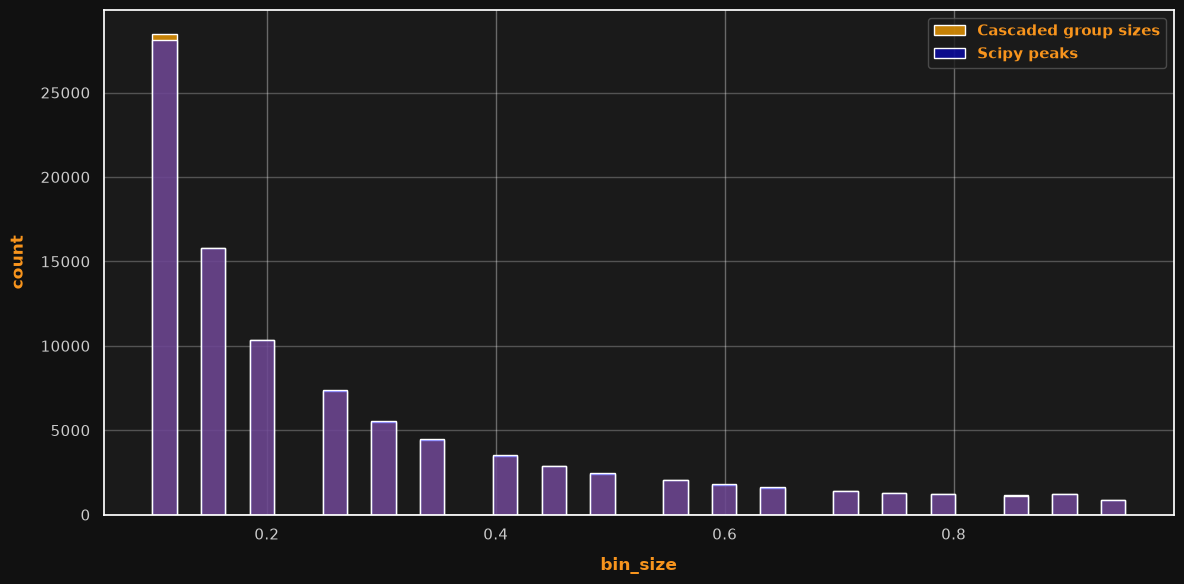

In [347]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), facecolor="#111111")
ax1.set_facecolor("#1a1a1a")
sns.histplot(data=cascadeDF, x="bin_size",color="orange", bins = 40,label="Cascaded group sizes")
sns.histplot(data=defect_summary, x="bin_size",color="blue", bins = 40, alpha = 0.5,label="Scipy peaks")
style_axis_labels(ax1, "bin_size", "count")
leg = ax1.legend(
    loc="upper right",
    frameon=True,
    facecolor="#1a1a1a",
    edgecolor="#555555",
    labelcolor=DV_ORANGE,
    fontsize=11,
)
for text in leg.get_texts():
    text.set_color(DV_ORANGE)
    text.set_fontweight("semibold")
ax1.grid(True, axis="y", alpha=0.25)
ax1.tick_params(axis="both", colors="#cccccc")
fig.tight_layout()
plt.show()

In [348]:
countsCascade = cascadeDF[['clip_id','anomaly_type']].groupby('clip_id').count().reset_index()
countsCascade.rename(columns={'anomaly_type':'count'},inplace = True)

countsDefect_summary = defect_summary[['anomaly_type','clip_id']].groupby('clip_id').count().reset_index()
countsDefect_summary.rename(columns={'anomaly_type':'count'},inplace = True)

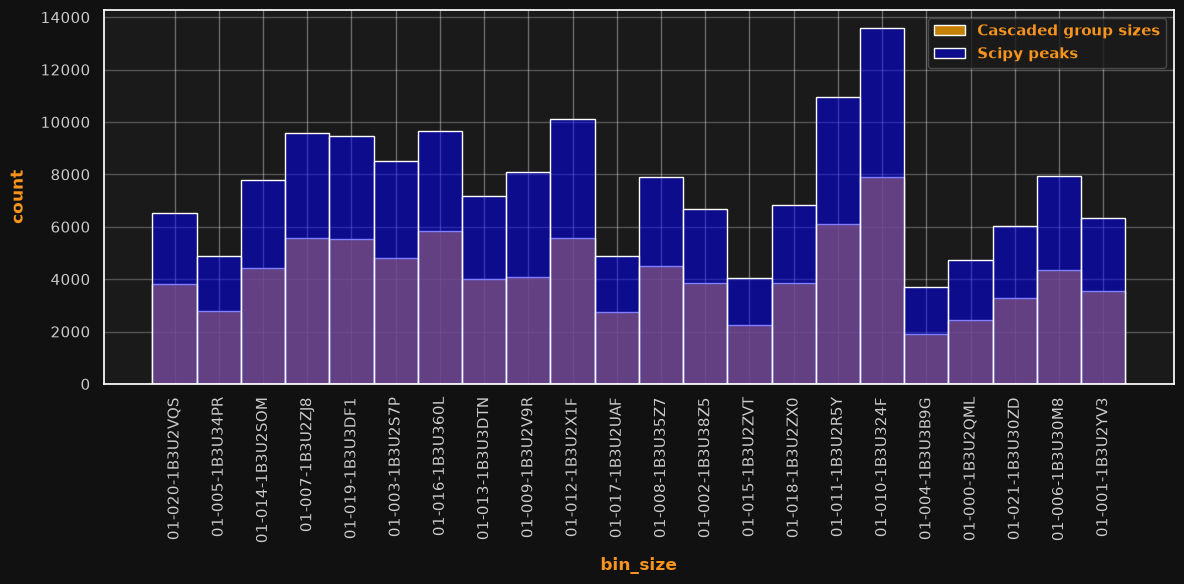

In [349]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), facecolor="#111111")
ax1.set_facecolor("#1a1a1a")
sns.histplot(data=cascadeDF, x="clip_id",color="orange", bins = 40,label="Cascaded group sizes")
sns.histplot(data=defect_summary, x="clip_id",color="blue", bins = 40, alpha = 0.5,label="Scipy peaks")
ax1.tick_params(axis="x", rotation=90)
style_axis_labels(ax1, "bin_size", "count")
leg = ax1.legend(
    loc="upper right",
    frameon=True,
    facecolor="#1a1a1a",
    edgecolor="#555555",
    labelcolor=DV_ORANGE,
    fontsize=11,
)
for text in leg.get_texts():
    text.set_color(DV_ORANGE)
    text.set_fontweight("semibold")
ax1.grid(True, axis="y", alpha=0.25)
ax1.tick_params(axis="both", colors="#cccccc")
fig.tight_layout()
plt.show()

# Compare with marked anomalies

In [204]:
# classified anomalies
anomalydf = pd.read_parquet('/home/sayakdg/ILIWorkflows/workflows/corrosion_sizing/merged_detection_parquets/anomalies_lower_prob_sampling_merged.parquet')
anomalydf = anomalydf[['anomaly_id', 'anomaly_status','track_index', 'start_odo_ticks', 'end_odo_ticks',
         'start_frame_idx', 'end_frame_idx','start_max_depth_mm', 'end_max_depth_mm', 'vol_conf', 'clip_id', 'vol_conf_grp',]]
anomalydf['cor_depth'] = anomalydf['end_max_depth_mm'] - anomalydf['start_max_depth_mm']
# change classification 
cor_depth = 0.2
anomalydf['anomaly_status'] = np.where(anomalydf['cor_depth'] > cor_depth,anomalydf['anomaly_status'],'ApprovedNotSized')

In [205]:
a = anomalydf.copy()
d = defect_summary.query('bin_size < 0.7').copy()
a["_a_idx"] = a.index
d["_d_idx"] = d.index
# exact keys
pairs = a.merge(d, on=["clip_id"], suffixes=("_a", "_d"))
# frame-interval overlap (not exact match)
overlaps = (
    (pairs["start_frame_idx_a"] <= pairs["end_frame_idx_d"])
    & (pairs["start_frame_idx_d"] <= pairs["end_frame_idx_a"])
)
merged = pairs.loc[overlaps].reset_index(drop=True)
merged

,anomaly_id,anomaly_status,track_index,start_odo_ticks_a,end_odo_ticks_a,start_frame_idx_a,end_frame_idx_a,start_max_depth_mm,end_max_depth_mm,vol_conf_a,...,start_odo_ticks_d,end_odo_ticks_d,start_frame_idx_d,end_frame_idx_d,vol_conf_d,id_corro_prob_mean,bin_size,length_odo,anomaly_type,_d_idx
0,1139583254454272,ApprovedNotSized,17,1283256084,1283256246,70932104,70932113,207.240393,207.377220,0.112815,...,1283255904,1283256354,70932094,70932118,0.112815,0.092937,0.10,450,ID_CORRO_POS,75535
1,1139583254454273,ApprovedNotSized,2,1285580172,1285580334,71039949,71039958,209.158105,209.276979,0.427241,...,1285579848,1285580604,71039932,71039973,0.427241,0.287070,0.40,756,ID_CORRO_POS,8676
2,1139583254454274,ApprovedNotSized,19,1286939136,1286939298,71122919,71122928,215.797891,215.919864,0.378422,...,1286938848,1286939532,71122904,71122941,0.378422,0.257708,0.35,684,ID_CORRO_POS,84163
3,1139583254454275,ApprovedNotSized,19,1286956758,1286956938,71123884,71123893,213.494315,213.634359,0.273537,...,1286956668,1286957100,71123879,71123902,0.273537,0.230494,0.25,432,ID_CORRO_POS,84164
4,1139583254454276,ApprovedNotSized,7,1289314896,1289314968,71260534,71260538,217.650728,217.766770,0.551046,...,1289314662,1289315148,71260521,71260548,0.551046,0.429282,0.55,486,ID_CORRO_POS,27745
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1185,1139583254458362,ApprovedNotSized,12,1277620674,1277620746,70618344,70618348,203.477567,203.636137,0.320886,...,1277620494,1277621016,70618334,70618363,0.320886,0.247403,0.30,522,ID_CORRO_POS,55448
1186,1139583254458363,Approved,12,1277627874,1277628036,70618744,70618753,202.939444,203.164517,0.580504,...,1277627694,1277628216,70618734,70618763,0.580504,0.449651,0.55,522,ID_CORRO_POS,55450
1187,1139583254458364,ApprovedNotSized,7,1279512624,1279512696,70718499,70718503,213.925710,214.003179,0.553479,...,1279512372,1279512984,70718485,70718518,0.553479,0.397738,0.55,612,ID_CORRO_POS,27721
1188,1139583254458365,Approved,17,1281600696,1281600768,70840744,70840748,201.646806,201.862555,0.304676,...,1281600516,1281601020,70840734,70840762,0.304676,0.226606,0.30,504,ID_CORRO_POS,75530


In [206]:
bins = np.sort(merged['bin_size'].unique())
df_defectivity = pd.DataFrame()
for bi in bins:
    df = merged.query('bin_size == @bi')
    total_count = len(defect_summary.query('bin_size == @bi'))
    sample_count = len(df)
    defect_count = len(df.query('anomaly_status == "Approved"'))
    df_summary = pd.DataFrame({
        'bin':[bi],
        'total_count': [total_count],
        'sample_count': [sample_count],
        'defect_count': [defect_count]
    })
    df_defectivity = pd.concat([df_defectivity,df_summary])


# counts: one row per bin with n_found, plus population size per bin
df_defectivity["p_hat"] = df_defectivity["defect_count"] / df_defectivity["sample_count"] 
df_defectivity["est_defects"] = np.round(df_defectivity["total_count"] * df_defectivity["p_hat"],0)

alpha = 0.5 + df_defectivity["defect_count"]
beta = 0.5 + 100 - df_defectivity["defect_count"]
df_defectivity["p_lo"] = stats.beta.ppf(0.025, alpha, beta)
df_defectivity["p_hi"] = stats.beta.ppf(0.975, alpha, beta)
df_defectivity["defects_lo"] = np.round(df_defectivity["total_count"] * df_defectivity["p_lo"],0)
df_defectivity["defects_hi"] = np.round(df_defectivity["total_count"] * df_defectivity["p_hi"],0)

# augment with Bayesian

# first smoothen the regression
iso = IsotonicRegression(increasing=True, out_of_bounds="clip")
df_defectivity["p_iso"] = iso.fit_transform(df_defectivity["bin"], df_defectivity["p_hat"])
df_defectivity["est_defects_iso"] = np.round(df_defectivity["total_count"] * df_defectivity["p_iso"],0)

# m = 0.5  # prior strength; tune this lower to trust the bin label less for prob
m = np.geomspace(0.5, 2.0, len(bins))  # exponential growth, length = number of bins
p_prior = df_defectivity["bin"]  # or whatever column holds the bin marker
a_post = m * p_prior + df_defectivity["defect_count"]
b_post = m * (1 - p_prior) + df_defectivity["sample_count"] - df_defectivity["defect_count"]
df_defectivity["p_posterior"] = a_post / (a_post + b_post)
df_defectivity["est_defects_bayesian"] = np.round(df_defectivity["total_count"] * df_defectivity["p_posterior"],0)
# df_defectivity["defects_lo_bayesian"] = np.round(df_defectivity["total_count"] * stats.beta.ppf(0.025, a_post, b_post),0)
# df_defectivity["defects_hi_bayesian"] = np.round(df_defectivity["total_count"] * stats.beta.ppf(0.975, a_post, b_post),0)

df_defectivity

,bin,total_count,sample_count,defect_count,p_hat,est_defects,p_lo,p_hi,defects_lo,defects_hi,p_iso,est_defects_iso,p_posterior,est_defects_bayesian
0,0.10,28304,98,3,0.030612,866.0,0.008520,0.077888,241.0,2205.0,0.030458,862.0,0.030964,876.0
0,0.15,15779,99,3,0.030303,478.0,0.008520,0.077888,134.0,1229.0,0.030458,481.0,0.030985,489.0
0,0.20,10300,100,5,0.050000,515.0,0.019332,0.106100,199.0,1093.0,0.040540,418.0,0.050959,525.0
0,0.25,7264,97,4,0.041237,300.0,0.013650,0.092290,99.0,670.0,0.040540,294.0,0.042796,311.0
0,0.30,5468,97,6,0.061856,338.0,0.025429,0.119475,139.0,653.0,0.040540,222.0,0.063871,349.0
0,0.35,4395,102,2,0.019608,86.0,0.004179,0.062606,18.0,275.0,0.040540,178.0,0.022621,99.0
0,0.40,3458,100,3,0.030000,104.0,0.008520,0.077888,29.0,269.0,0.040540,140.0,0.033899,117.0
0,0.45,2847,100,7,0.070000,199.0,0.031855,0.132509,91.0,377.0,0.069653,198.0,0.074536,212.0
0,0.50,2401,101,7,0.069307,166.0,0.031855,0.132509,76.0,318.0,0.069653,167.0,0.075072,180.0
0,0.55,2029,97,14,0.144330,293.0,0.082566,0.217898,168.0,442.0,0.131376,267.0,0.150728,306.0


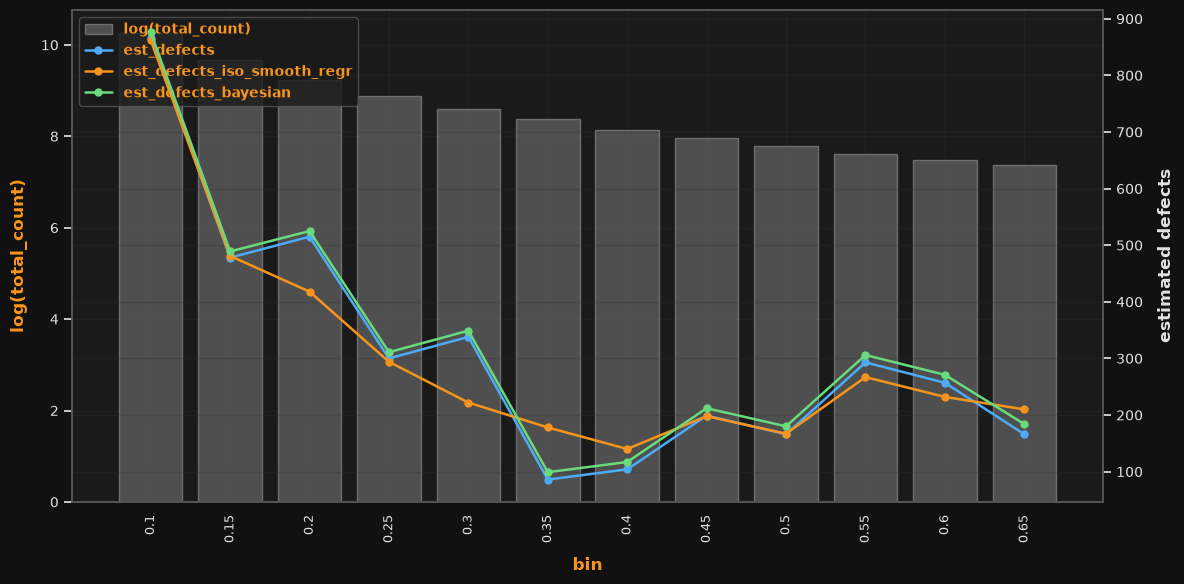

In [207]:

DV_ORANGE = "#F7941D"
TEXT      = "#e0e0e0"
GRID      = "#333333"
def style_axis_labels(ax, ylabel, color=DV_ORANGE):
    ax.set_ylabel(ylabel, color=color, fontsize=12, fontweight="bold", labelpad=10)
    ax.tick_params(axis="y", colors=TEXT, labelsize=10)

def style_legend(ax, handles, labels, loc="upper right"):
    leg = ax.legend(
        handles, labels,
        loc=loc,
        frameon=True,
        facecolor="#1a1a1a",
        edgecolor="#555555",
        labelcolor=DV_ORANGE,
        fontsize=10,
    )
    for text in leg.get_texts():
        text.set_color(DV_ORANGE)
        text.set_fontweight("semibold")
    return leg

fig, ax1 = plt.subplots(figsize=(12, 6), facecolor="#111111")
ax1.set_facecolor("#1a1a1a")

x = np.arange(len(df_defectivity))

ax1.bar(
    x,
    np.log(df_defectivity["total_count"]),
    color="#666666",
    alpha=0.7,
    edgecolor="#888888",
    label="log(total_count)",
)
style_axis_labels(ax1, "log(total_count)")

ax2 = ax1.twinx()
ax2.set_facecolor("#1a1a1a")

ax2.plot(x, df_defectivity["est_defects"], "o-",
         color="#4dabf7", markersize=5, linewidth=1.8, label="est_defects")
ax2.plot(x, df_defectivity["est_defects_iso"], "o-",
         color=DV_ORANGE, markersize=5, linewidth=1.8, label="est_defects_iso_smooth_regr")
ax2.plot(x, df_defectivity["est_defects_bayesian"], "o-",
         color="#69db7c", markersize=5, linewidth=1.8, label="est_defects_bayesian")
style_axis_labels(ax2, "estimated defects", color=TEXT)

# x-axis
ax1.set_xlabel("bin", color=DV_ORANGE, fontsize=12, fontweight="bold", labelpad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(df_defectivity["bin"], rotation=90, color=TEXT, fontsize=9)
ax1.tick_params(axis="x", colors=TEXT)

# spines & grid
for ax in (ax1, ax2):
    ax.grid(True, alpha=0.25, color=GRID)
    for spine in ax.spines.values():
        spine.set_color("#555555")

# combined legend — only once, styled
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
style_legend(ax1, h1 + h2, l1 + l2, loc="upper left")

fig.tight_layout()
plt.show()

In [208]:
statuses = ["Approved", "ApprovedNotSized"]  # adjust to exact strings in merged

counts =  merged.query("anomaly_status in @statuses").groupby(["bin_size", "anomaly_status"], as_index=False).size().rename(columns={"size": "n_defects"})

pivot = (
    counts.groupby(["bin_size", "anomaly_status"], as_index=False)["n_defects"]
    .sum()
    .pivot(index="bin_size", columns="anomaly_status", values="n_defects")
)

# rename to match your exact status strings if needed
pivot["percent_approved_ratio"] = (
    100*pivot["Approved"] / pivot["ApprovedNotSized"]
)

pivot["precision"] = pivot["Approved"] / (pivot["ApprovedNotSized"] + pivot["Approved"])

counts = counts.merge(
    pivot[["percent_approved_ratio",'precision']],
    left_on="bin_size",
    right_index=True,
    how="left",
)

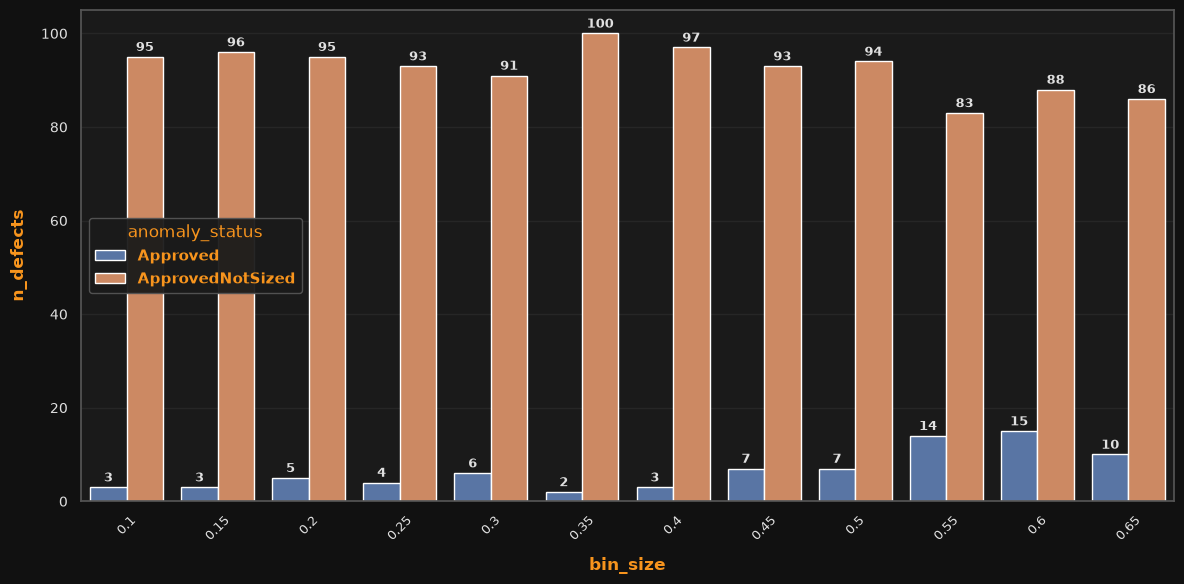

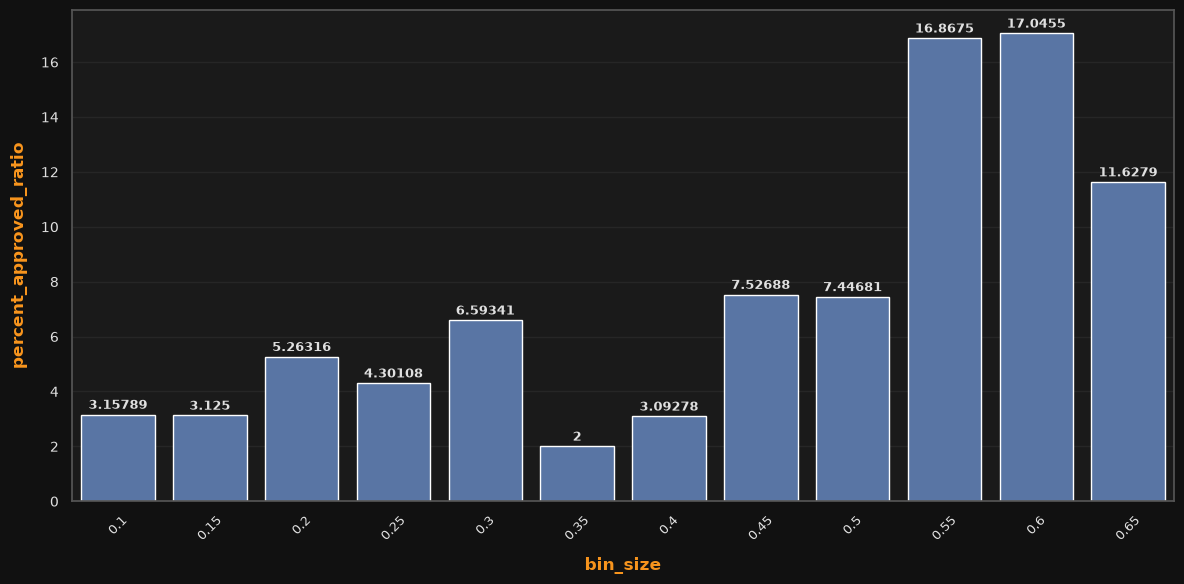

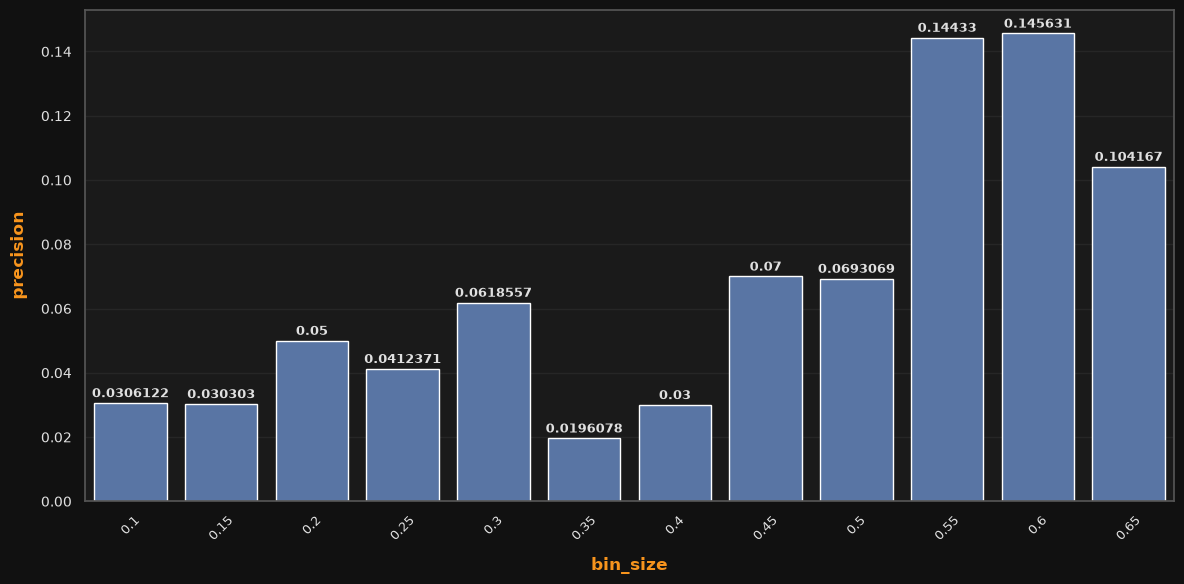

In [211]:
def style_dark_barplot(ax, xlabel, ylabel, title=None):
    ax.set_facecolor("#1a1a1a")
    ax.set_xlabel(xlabel, color=DV_ORANGE, fontsize=12, fontweight="bold", labelpad=10)
    ax.set_ylabel(ylabel, color=DV_ORANGE, fontsize=12, fontweight="bold", labelpad=10)
    if title:
        ax.set_title(title, color="#ffffff", fontsize=13, pad=12)
    ax.tick_params(axis="x", colors=TEXT, labelsize=9)
    ax.tick_params(axis="y", colors=TEXT, labelsize=10)
    ax.grid(True, axis="y", alpha=0.5, color=GRID)
    for spine in ax.spines.values():
        spine.set_color("#555555")
def style_legend(ax):
    leg = ax.get_legend()
    if leg is None:
        return
    leg.set_frame_on(True)
    leg.get_frame().set_facecolor("#1a1a1a")
    leg.get_frame().set_edgecolor("#555555")
    leg.get_frame().set_alpha(0.95)
    for text in leg.get_texts():
        text.set_color(DV_ORANGE)
        text.set_fontweight("semibold")
    if leg.get_title() is not None:
        leg.get_title().set_color(DV_ORANGE)
def label_bars(ax, color=TEXT, fontsize=9):
    for container in ax.containers:
        ax.bar_label(container, fontsize=fontsize, color=color, fontweight="semibold", padding=2)

fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), facecolor="#111111")
ax = sns.barplot(data=counts, x="bin_size", y="n_defects", hue="anomaly_status")
style_dark_barplot(ax1, "bin_size", "n_defects")
style_legend(ax1)
label_bars(ax1)
ax1.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), facecolor="#111111")
ax = sns.barplot(data=counts, x="bin_size", y="percent_approved_ratio")
style_dark_barplot(ax1, "bin_size", "percent_approved_ratio")
label_bars(ax1)
ax1.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), facecolor="#111111")
ax = sns.barplot(data=counts, x="bin_size", y="precision")
style_dark_barplot(ax1, "bin_size", "precision")
label_bars(ax1)
ax1.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

# Frequency stats

In [376]:
defect_summary

,defect_marker,clip_id,track_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,id_corro_prob_mean,bin_size,length_odo,anomaly_type
0,1,01-000-1B3U2QML,0,42846,42900,329,332,0.176388,0.145232,0.15,54,ID_CORRO_POS
1,2,01-000-1B3U2QML,0,43008,43242,338,351,0.585590,0.481919,0.55,234,ID_CORRO_POS
2,3,01-000-1B3U2QML,0,43260,43350,352,357,0.248364,0.240537,0.20,90,ID_CORRO_POS
3,4,01-000-1B3U2QML,0,54366,54600,969,982,0.068328,0.061484,NaN,234,ID_CORRO_POS
4,5,01-000-1B3U2QML,0,61656,62088,1374,1398,0.101867,0.088915,0.10,432,ID_CORRO_POS
...,...,...,...,...,...,...,...,...,...,...,...,...
165261,285459,01-021-1B3U30ZD,21,1749706236,1749706938,96708249,96708288,0.597685,0.359072,0.55,702,ID_CORRO_POS
165262,285461,01-021-1B3U30ZD,21,1749720726,1749721032,96709054,96709071,0.299531,0.244355,0.25,306,ID_CORRO_POS
165263,285462,01-021-1B3U30ZD,21,1749721716,1749722022,96709109,96709126,0.115102,0.104285,0.10,306,ID_CORRO_POS
165264,285463,01-021-1B3U30ZD,21,1749722040,1749724848,96709127,96709283,0.159725,0.125163,0.15,2808,ID_CORRO_POS


In [398]:
WINDOW = 500_000  # frames per bucket

ds = defect_summary.dropna(subset=["bin_size"]).copy()
ds["bin_size"] = ds["bin_size"].round(2)  # avoid float-cut noise (0.70 vs 0.7000001)

# one window per defect; start is enough at this window size
ds["odo_window"] = ds["start_odo_ticks"] // WINDOW
ds["window_start"] = ds["odo_window"] * WINDOW
ds["window_end"] = ds["window_start"] + WINDOW - 1  # inclusive

# long form: one row per (window, bin)
freq = (
    ds.groupby(["track_id","odo_window", "window_start", "window_end", "bin_size"], as_index=False)
    .size()
    .rename(columns={"size": "n_defects"})
)

freq

,track_id,odo_window,window_start,window_end,bin_size,n_defects
0,0,0,0,499999,0.10,3
1,0,0,0,499999,0.15,1
2,0,0,0,499999,0.20,1
3,0,0,0,499999,0.55,1
4,0,3,1500000,1999999,0.10,1
...,...,...,...,...,...,...
66473,21,3499,1749500000,1749999999,0.15,2
66474,21,3499,1749500000,1749999999,0.25,1
66475,21,3499,1749500000,1749999999,0.35,2
66476,21,3499,1749500000,1749999999,0.50,1


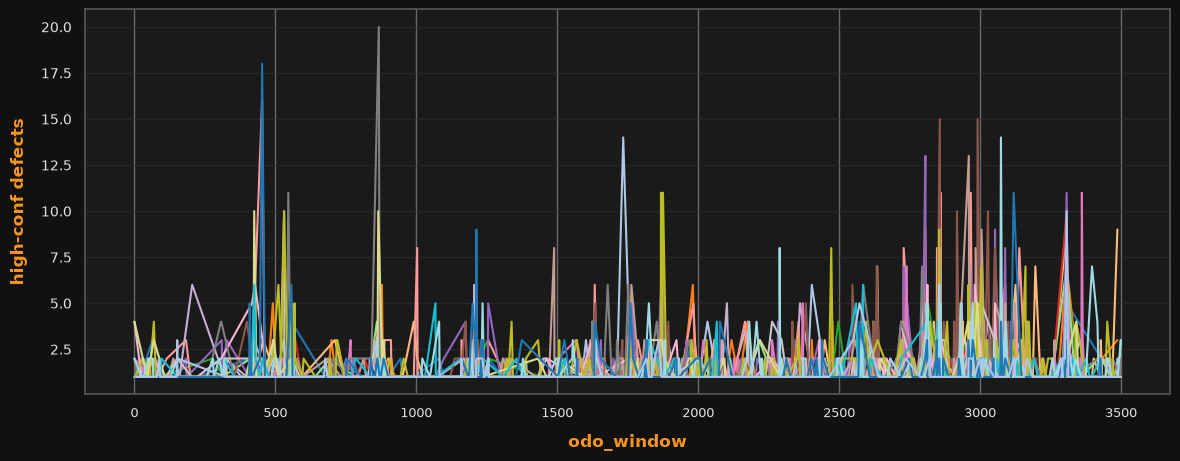

In [399]:
high = (
    freq.query("bin_size >= 0.7")
    .groupby(["track_id", "odo_window", "window_start"], as_index=False)["n_defects"]
    .sum()
)

fig, ax = plt.subplots(figsize=(14, 5), facecolor="#111111")
sns.lineplot(data=high, x="odo_window", y="n_defects", hue="track_id",
             palette="tab20", legend=False, ax=ax)
style_dark_barplot(ax, "odo_window", "high-conf defects")

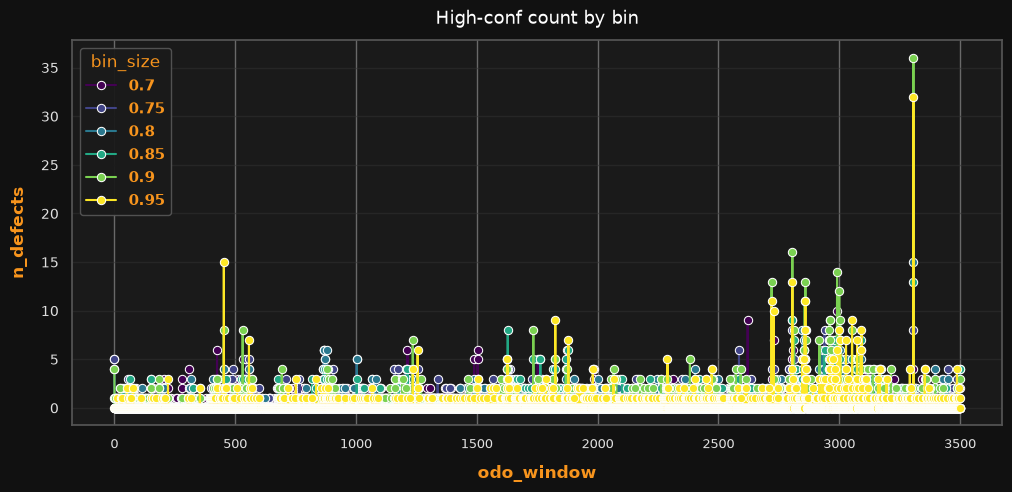

In [400]:
fig, ax = plt.subplots(figsize=(12, 5), facecolor="#111111")
sns.lineplot(
    data=freq_long.query("bin_size >= 0.7"),
    x="odo_window",
    y="n_defects",
    hue="bin_size",
    marker="o",
    palette="viridis",
    ax=ax,
)
style_dark_barplot(ax, "odo_window", "n_defects", title="High-conf count by bin")
style_legend(ax)

Text(140.97222222222223, 0.5, 'track_id')

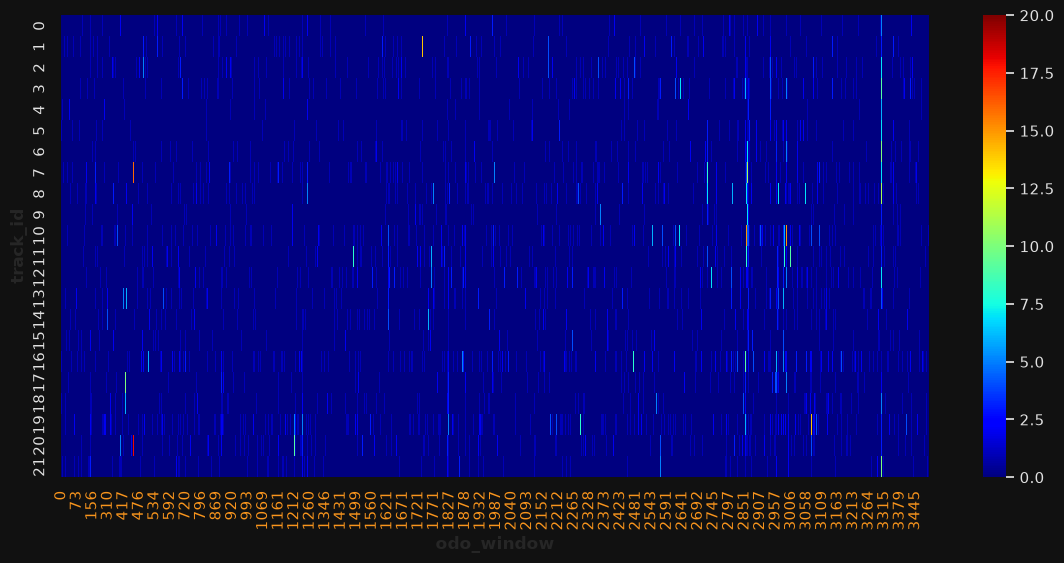

In [401]:
heat = (
    high.pivot_table(index="track_id", columns="odo_window", values="n_defects", fill_value=0)
    .astype(int)
)

fig, ax = plt.subplots(figsize=(14, 6), facecolor="#111111")
sns.heatmap(heat, cmap="jet", ax=ax)
ax.set_xlabel("odo_window")
ax.set_ylabel("track_id")